In [1]:
# cell 1: setup, kaggle login, download and extract the dataset
# dataset: phhasian0710/seed-iv

import os
import sys
import json
import shutil
import subprocess
from pathlib import Path

# folders for the project
PROJECT_DIR = Path("/content/seed_project")
DATA_DIR = PROJECT_DIR / "data"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

# kaggle dataset name
DATASET_ID = "phhasian0710/seed-iv"

print("=" * 65)
print("SEED EEG EMOTION RECOGNITION PROJECT")
print("=" * 65)
print("Python  :", sys.version.split()[0])
print("Project :", PROJECT_DIR)
print("Dataset :", DATASET_ID)

# install kaggle so we can download the data
print("\n[1/6] Installing Kaggle CLI...")

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "kaggle"],
    check=True
)

# kaggle needs the api key file to log in
print("\n[2/6] Configuring Kaggle credentials...")

KAGGLE_DIR = Path.home() / ".kaggle"
KAGGLE_DIR.mkdir(parents=True, exist_ok=True)
KAGGLE_JSON = KAGGLE_DIR / "kaggle.json"

# if the key is not saved already, ask for the upload
if not KAGGLE_JSON.exists():
    from google.colab import files

    print("Upload your NEW kaggle.json file.")
    print("Do not upload an old/revoked API key.")

    uploaded = files.upload()

    if "kaggle.json" not in uploaded:
        raise RuntimeError(
            "kaggle.json was not uploaded. "
            "Run this cell again and select kaggle.json."
        )

    with open(KAGGLE_JSON, "wb") as f:
        f.write(uploaded["kaggle.json"])

    # only the owner should be able to read the key
    os.chmod(KAGGLE_JSON, 0o600)

# check the file has username and key (key is not printed)
try:
    with open(KAGGLE_JSON, "r") as f:
        credentials = json.load(f)

    if not credentials.get("username") or not credentials.get("key"):
        raise ValueError("JSON must contain username and key.")

except Exception as e:
    raise RuntimeError(
        f"Invalid kaggle.json: {e}. "
        "Download a fresh token from Kaggle settings."
    )

print("Credentials file found and JSON format validated.")

# tell kaggle where the key is stored
env = os.environ.copy()
env["KAGGLE_CONFIG_DIR"] = str(KAGGLE_DIR)

# list the dataset files to confirm login works
print("\n[3/6] Testing Kaggle access...")

test = subprocess.run(
    ["kaggle", "datasets", "files", DATASET_ID],
    env=env,
    capture_output=True,
    text=True
)

if test.returncode != 0:
    print("\nKaggle returned this error:")
    print(test.stderr[-3000:])

    raise RuntimeError(
        "Could not access the dataset. Check your Kaggle API key, "
        "internet connection, and access to the dataset page. "
        "Fix the problem and rerun this cell."
    )

print("Authentication and dataset access successful.\n")
print(test.stdout[:2500])

# download the zip and unzip it into the data folder
print("\n[4/6] Downloading and extracting dataset...")
print("This may take several minutes depending on download speed.")

download = subprocess.run(
    [
        "kaggle", "datasets", "download",
        DATASET_ID,
        "--path", str(DATA_DIR),
        "--unzip"
    ],
    env=env,
    text=True
)

if download.returncode != 0:
    raise RuntimeError(
        "Download/extraction failed. Read the error above, "
        "fix the issue, and rerun this cell."
    )

print("Download/extraction command completed.")

# look at what got downloaded
print("\n[5/6] Inspecting dataset contents...")

all_files = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file()
]

total_bytes = sum(p.stat().st_size for p in all_files)

print("\nData directory  :", DATA_DIR)
print("Number of files :", len(all_files))
print("Total size (GB) :", round(total_bytes / (1024 ** 3), 3))

# print first 80 files with their sizes
print("\nFirst 80 files:")
print("-" * 70)
print(f"{'file':<55}{'size (MB)':>12}")
print("-" * 70)
for p in all_files[:80]:
    print(
        f"{str(p.relative_to(DATA_DIR)):<55}"
        f"{p.stat().st_size / (1024 ** 2):>12.2f}"
    )

if len(all_files) > 80:
    print("-" * 70)
    print(f"... plus {len(all_files) - 80} more files")

# count files by type
mat_files = [
    p for p in all_files
    if p.suffix.lower() == ".mat"
]

csv_files = [
    p for p in all_files
    if p.suffix.lower() == ".csv"
]

npy_files = [
    p for p in all_files
    if p.suffix.lower() == ".npy"
]

print("\nFile type counts:")
print("-" * 25)
print(f"{'MAT files':<15}{len(mat_files):>10}")
print(f"{'CSV files':<15}{len(csv_files):>10}")
print(f"{'NPY files':<15}{len(npy_files):>10}")

# find eeg, label and readme files
eeg_related = [
    p for p in all_files
    if any(term in str(p).lower() for term in [
        "eeg_raw_data",
        "eeg_feature_smooth",
        "label",
        "readme"
    ])
]

print("\nEEG/label/README-related files (first 40):")
print("-" * 70)
for p in eeg_related[:40]:
    print(" ", p.relative_to(DATA_DIR))

# save the file list as json so we can check it later
print("\n[6/6] Saving dataset inventory...")

inventory = {
    "dataset_id": DATASET_ID,
    "project_directory": str(PROJECT_DIR),
    "data_directory": str(DATA_DIR),
    "number_of_files": len(all_files),
    "total_size_bytes": total_bytes,
    "mat_files": len(mat_files),
    "csv_files": len(csv_files),
    "npy_files": len(npy_files),
    "files": [
        {
            "path": str(p.relative_to(DATA_DIR)),
            "size_bytes": p.stat().st_size,
            "extension": p.suffix.lower()
        }
        for p in all_files
    ]
}

inventory_path = PROJECT_DIR / "dataset_inventory.json"

with open(inventory_path, "w") as f:
    json.dump(inventory, f, indent=2)

print("Inventory saved:", inventory_path)

# stop if nothing was extracted
if not all_files:
    raise RuntimeError(
        "No dataset files were found after extraction. "
        "Inspect the Kaggle output before proceeding."
    )

print("\n" + "=" * 65)
print("CELL 1 COMPLETED")
print("Dataset directory :", DATA_DIR)
print("Inventory         :", inventory_path)
print("=" * 65)

SEED EEG EMOTION RECOGNITION PROJECT
Python  : 3.13.18
Project : /content/seed_project
Dataset : phhasian0710/seed-iv

[1/6] Installing Kaggle CLI...

[2/6] Configuring Kaggle credentials...
Upload your NEW kaggle.json file.
Do not upload an old/revoked API key.


Saving kaggle.json to kaggle.json
Credentials file found and JSON format validated.

[3/6] Testing Kaggle access...
Authentication and dataset access successful.

Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7ilOwiSZpIOrk26PWUEJV-Dfvj8qDtcmip6cdEbAKzz3X_mJlGx0n2HOzBqyWFNzuOd_MNjUeakoxYsCVUJypHBfosdjVea2wKKTC2sHxLXeBLCuuJg8MmnYZIUxTEJYS1VnHYtyE8EBWc
name                                     size  creationDate                
------------------------------------  -------  --------------------------  
Channel Order.xlsx                      10370  2019-10-25 03:50:06.094000  
ReadMe.txt                               1431  2019-10-25 03:51:30.933000  
eeg_feature_smooth/1/10_20151014.mat  7801112  2019-10-25 03:50:06.322000  
eeg_feature_smooth/1/11_20150916.mat  7820707  2019-10-25 03:50:06.311000  
eeg_feature_smooth/1/12_20150725.mat  7823040  2019-10-25 03:50:06.478000  
eeg_feature_smooth/1/13_20151115.mat  7810321  2019-10-25 03:50:06.429000  
eeg_feature_smooth/1/14_20151205.mat  77528

In [3]:
# cell 2: inspect the files, check shapes and sampling rate, choose the subset

import re
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.io as sio
from IPython.display import display, HTML
warnings.filterwarnings("ignore")

# reuse the path from cell 1, or fall back to the known folder
try:
    DATA_DIR = Path(DATA_DIR)
except NameError:
    DATA_DIR = Path("/content/seed_project/data")
PROJECT_DIR = DATA_DIR.parent
CACHE_DIR = PROJECT_DIR / "cache"
CACHE_DIR.mkdir(exist_ok=True)


# helpers to show headings and neat tables with space after them
def section(title):
    display(HTML(f"<h2 style='margin-top:40px;margin-bottom:8px;"
                 f"border-bottom:2px solid #888;padding-bottom:4px'>{title}</h2>"))

def gap(px=30):
    display(HTML(f"<div style='height:{px}px'></div>"))

def show(table, caption, fmt=None, index=False):
    try:
        sty = (table.style.format(fmt or {}, na_rep="-").set_caption(caption)
               .set_table_styles([
                   dict(selector="caption", props=[("caption-side", "top"), ("text-align", "left"),
                                                   ("font-size", "15px"), ("font-weight", "bold"),
                                                   ("padding", "0 0 8px 0")]),
                   dict(selector="th", props=[("padding", "7px 18px"), ("text-align", "center")]),
                   dict(selector="td", props=[("padding", "7px 18px"), ("text-align", "center")])]))
        if not index:
            sty = sty.hide(axis="index")
        display(sty)
    except Exception:
        display(table)
    gap()


# 1. size of each top level folder
section("1) Size by folder")

sizes = {}
for p in DATA_DIR.rglob("*"):
    if p.is_file():
        top = p.relative_to(DATA_DIR).parts[0]
        n, b = sizes.get(top, (0, 0))
        sizes[top] = (n + 1, b + p.stat().st_size)

size_tbl = pd.DataFrame([(k, n, b / 1e9) for k, (n, b) in sorted(sizes.items())],
                        columns=["Folder", "Files", "Size (GB)"])
show(size_tbl, "Files and size in each folder", {"Files": "{:,.0f}", "Size (GB)": "{:.3f}"})


# 2. readme files (the emotion labels are written here)
section("2) Readme content")

for rp in sorted(DATA_DIR.rglob("ReadMe.txt")):
    print(f"--- {rp.relative_to(DATA_DIR)} ---\n")
    print(rp.read_text(errors="ignore"))
gap()


# 3. channel order file
section("3) Channel order")

try:
    ch = pd.read_excel(DATA_DIR / "Channel Order.xlsx", header=None)
    print("shape:", ch.shape)
    gap(10)
    show(ch.head(8), "First 8 rows of the channel order file", index=True)
except Exception as e:
    print("could not read Channel Order.xlsx:", repr(e))
    gap()


# 4. list all the eeg recording files
section("4) EEG recording inventory")

eeg_dirs = [p for p in DATA_DIR.rglob("eeg_raw_data") if p.is_dir()]
print("eeg_raw_data folders found:", [str(p.relative_to(DATA_DIR)) for p in eeg_dirs])
assert eeg_dirs, "eeg_raw_data folder not found, check the folder listing from cell 1"
EEG_DIR = eeg_dirs[0]
gap(10)

# file names look like 1_20150915.mat, inside a folder named by session
pat = re.compile(r"^(\d+)_(\d{8})\.mat$")
rows = []
for p in EEG_DIR.rglob("*.mat"):
    m = pat.match(p.name)
    if m and p.parent.name.isdigit():
        rows.append(dict(session=int(p.parent.name), subject=int(m.group(1)),
                         date=m.group(2), size_mb=p.stat().st_size / 1e6, path=str(p)))
df = pd.DataFrame(rows).sort_values(["session", "subject"]).reset_index(drop=True)

summary = pd.DataFrame({
    "Item": ["EEG files", "Subjects", "Sessions", "Smallest file (MB)",
             "Average file (MB)", "Largest file (MB)", "Total size (GB)"],
    "Value": [len(df), df.subject.nunique(), str(sorted(df.session.unique())),
              f"{df.size_mb.min():.0f}", f"{df.size_mb.mean():.0f}",
              f"{df.size_mb.max():.0f}", f"{df.size_mb.sum() / 1e3:.2f}"]})
show(summary, "Summary of all EEG files")

per_session = df.groupby("session").size().reset_index(name="Files")
per_session.columns = ["Session", "Files"]
show(per_session, "Files per session")


# 5. look inside one file
section("5) Inspect one file (session 1, first subject)")

first = df[(df.session == 1) & (df.subject == df[df.session == 1].subject.min())].iloc[0]
print("file:", Path(first.path).relative_to(DATA_DIR))
gap(10)

# whosmat reads only the header, so it is fast
info = sio.whosmat(first.path)
trial_info = []
for name, shape, dtype in info:
    m = re.search(r"eeg(\d+)$", name)
    if m:
        trial_info.append((int(m.group(1)), name, shape, dtype))
trial_info.sort()

print("variables in file    :", len(info))
print("eeg trial variables  :", len(trial_info))
print("non trial variables  :", [n for n, _, _ in info if not re.search(r"eeg\d+$", n)])
gap(10)

# duration at 200 hz and 1000 hz, to guess the real sampling rate
trial_tbl = pd.DataFrame([(t, name, str(shape), str(dtype), max(shape) / 200, max(shape) / 1000)
                          for t, name, shape, dtype in trial_info],
                         columns=["Trial", "Variable", "Shape", "Dtype",
                                  "Duration @200 Hz (s)", "Duration @1000 Hz (s)"])
show(trial_tbl, "Trials in this file",
     {"Duration @200 Hz (s)": "{:.1f}", "Duration @1000 Hz (s)": "{:.1f}"})

# load just one trial and check the values
k1 = trial_info[0][1]
mat1 = sio.loadmat(first.path, variable_names=[k1])
x = np.asarray(mat1[k1])

check_tbl = pd.DataFrame({
    "Check": ["Shape", "Dtype", "NaN count", "Inf count", "Minimum", "Maximum",
              "Mean", "Std", "Channel axis (62 expected)"],
    "Value": [str(x.shape), str(x.dtype), int(np.isnan(x).sum()), int(np.isinf(x).sum()),
              f"{x.min():.2f}", f"{x.max():.2f}", f"{x.mean():.3f}", f"{x.std():.3f}",
              str([i for i, s in enumerate(x.shape) if s == 62])]})
show(check_tbl, f"Value check on {k1}")

# total length of the recording tells us the sampling rate
tot = sum(max(s) for _, _, s, _ in trial_info)
rate_tbl = pd.DataFrame({"If sampling rate is": ["200 Hz", "1000 Hz"],
                         "Total recording (min)": [tot / 200 / 60, tot / 1000 / 60]})
show(rate_tbl, f"Total samples per channel = {tot}", {"Total recording (min)": "{:.1f}"})


# 6. pick the small subset used in the later cells
section("6) Working subset")

SUBSET_SESSIONS = [1]
# first 5 subjects of session 1 only
SUBSET_SUBJECTS = sorted(df[df.session == 1].subject.unique())[:5]
subset = df[df.session.isin(SUBSET_SESSIONS) & df.subject.isin(SUBSET_SUBJECTS)].reset_index(drop=True)

print("sessions :", SUBSET_SESSIONS)
print("subjects :", SUBSET_SUBJECTS)
print("files    :", len(subset))
print(f"size     : {subset.size_mb.sum() / 1e3:.2f} GB")
gap(10)

sub_tbl = subset[["session", "subject", "date", "size_mb"]].copy()
sub_tbl.columns = ["Session", "Subject", "Date", "Size (MB)"]
show(sub_tbl, "Files chosen for the project", {"Size (MB)": "{:.1f}"})

subset.to_csv(CACHE_DIR / "subset_files.csv", index=False)
print("saved subset list ->", CACHE_DIR / "subset_files.csv")
gap(10)

section("Cell 2 completed")
print("variables kept: df, subset, EEG_DIR, trial_info, DATA_DIR, CACHE_DIR")

Folder,Files,Size (GB)
Channel Order.xlsx,1,0.000
ReadMe.txt,1,0.000
eeg_feature_smooth,45,0.344
eeg_raw_data,45,7.024
eye_feature_smooth,45,0.009
eye_raw_data,270,0.005
seed_iv,407,7.446


--- ReadMe.txt ---

SJTU Emotion EEG Dataset for Four Emotions (SEED-IV)
This is a subset of SEED (SJTU Emotion EEG Dataset: http://bcmi.sjtu.edu.cn/~seed/) for emotion recognition

Copyright:
Center for Brain-like Computing and Machine Intelligence, Department of Computer Science and Engineering, Shanghai Jiao Tong University, China
Key Laboratory of Shanghai Education Commission for Intelligent Interaction and Cognitive Engineering, Shanghai Jiao Tong University, China
Brain Science and Technology Research Center, Shanghai Jiao Tong University, China

Label:
The labels of the three sessions for the same subjects are as follows,
session1_label = [1,2,3,0,2,0,0,1,0,1,2,1,1,1,2,3,2,2,3,3,0,3,0,3];
session2_label = [2,1,3,0,0,2,0,2,3,3,2,3,2,0,1,1,2,1,0,3,0,1,3,1];
session3_label = [1,2,2,1,3,3,3,1,1,2,1,0,2,3,3,0,2,3,0,0,2,0,1,0];

The labels with 0, 1, 2, and 3 denote the ground truth, neutral, sad, fear, and happy emotions, respectively.

The size of the sliding time windows for featu

shape: (62, 1)


,0
0,FP1
1,FPZ
2,FP2
3,AF3
4,AF4
5,F7
6,F5
7,F3


eeg_raw_data folders found: ['eeg_raw_data', 'seed_iv/eeg_raw_data']


...

If sampling rate is,Total recording (min)
200 Hz,57.3
1000 Hz,11.5


sessions : [1]
subjects : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
files    : 5
size     : 0.81 GB


Session,Subject,Date,Size (MB)
1,1,20160518,159.3
1,2,20150915,150.8
1,3,20150919,170.9
1,4,20151111,166.3
1,5,20160406,161.1


saved subset list -> /content/seed_project/cache/subset_files.csv


variables kept: df, subset, EEG_DIR, trial_info, DATA_DIR, CACHE_DIR


In [4]:
# cell 3: load the subset, attach labels, cut trials into segments, run checks

import re
import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.io as sio
from scipy import signal
from IPython.display import display, HTML
warnings.filterwarnings("ignore")
t0 = time.time()

# reuse the path from earlier cells, or fall back to the known folder
try:
    DATA_DIR = Path(DATA_DIR)
except NameError:
    DATA_DIR = Path("/content/seed_project/data")
PROJECT_DIR = DATA_DIR.parent
CACHE_DIR = PROJECT_DIR / "cache"
CACHE_DIR.mkdir(exist_ok=True)
subset = pd.read_csv(CACHE_DIR / "subset_files.csv")


# helpers for headings, neat tables and spacing (output only)
def section(title):
    display(HTML(f"<h2 style='margin-top:40px;margin-bottom:8px;"
                 f"border-bottom:2px solid #888;padding-bottom:4px'>{title}</h2>"))

def gap(px=30):
    display(HTML(f"<div style='height:{px}px'></div>"))

def show(table, caption, fmt=None, index=False):
    try:
        sty = (table.style.format(fmt or {}, na_rep="-").set_caption(caption)
               .set_table_styles([
                   dict(selector="caption", props=[("caption-side", "top"), ("text-align", "left"),
                                                   ("font-size", "15px"), ("font-weight", "bold"),
                                                   ("padding", "0 0 8px 0")]),
                   dict(selector="th", props=[("padding", "7px 18px"), ("text-align", "center")]),
                   dict(selector="td", props=[("padding", "7px 18px"), ("text-align", "center")])]))
        if not index:
            sty = sty.hide(axis="index")
        display(sty)
    except Exception:
        display(table)
    gap()


# settings
FS = 200                  # data is already 200 hz (seen in cell 2), so no resampling
SEG_LEN = 1024            # samples in one instance (5.12 s)
MAX_SEG_PER_TRIAL = 12    # max segments taken from each trial, to keep it fast
N_CH = 62
CLASS_NAMES = ["neutral", "sad", "fear", "happy"]   # 0,1,2,3 as in the readme

# emotion label of each of the 24 trials, copied from the readme
LABELS = {
    1: [1,2,3,0,2,0,0,1,0,1,2,1,1,1,2,3,2,2,3,3,0,3,0,3],
    2: [2,1,3,0,0,2,0,2,3,3,2,3,2,0,1,1,2,1,0,3,0,1,3,1],
    3: [1,2,2,1,3,3,3,1,1,2,1,0,2,3,3,0,2,3,0,0,2,0,1,0],
}
for s, l in LABELS.items():
    assert len(l) == 24, f"session {s}: expected 24 labels"

# variable names start with the subject's initials (cz_eeg1, ha_eeg1), so match on "eeg<number>"
TRIAL_RE = re.compile(r"eeg(\d+)$")

def trial_keys(mat_keys):
    d = {}
    for k in mat_keys:
        m = TRIAL_RE.search(k)
        if m and not k.startswith("__"):
            d[int(m.group(1))] = k
    return d   # {trial number: variable name}


# 1. spectrum check, is the data already low-passed at 75 hz?
section("1) Spectrum check")
print(f"subject {subset.subject[0]}, session {subset.session[0]}, trial 1")
gap(10)

names0 = trial_keys([n for n, _, _ in sio.whosmat(subset.path[0])])
ex = sio.loadmat(subset.path[0], variable_names=[names0[1]])[names0[1]]
f, Pxx = signal.welch(ex, fs=FS, nperseg=1024, axis=1)
Pm = Pxx.mean(axis=0)

def band(lo, hi):
    return Pm[(f >= lo) & (f < hi)].mean()

ref = band(10, 40)   # reference power level
bands = [(0, 1), (1, 4), (4, 8), (8, 13), (13, 30), (30, 50), (50, 75), (75, 80), (80, 100)]
band_tbl = pd.DataFrame({"Band (Hz)": [f"{lo} - {hi}" for lo, hi in bands],
                         "Power relative to 10-40 Hz": [band(lo, hi) / ref for lo, hi in bands]})
show(band_tbl, "Average power in each frequency band", {"Power relative to 10-40 Hz": "{:.5f}"})

# if power above 80 hz is tiny, the data was already low-passed
ratio = band(80, 100) / ref
ALREADY_LP = bool(ratio < 0.01)
apply_lp = not ALREADY_LP

print(f"power(80-100 Hz) / power(10-40 Hz) = {ratio:.5f}")
print(f"already low-passed at about 75 Hz : {ALREADY_LP}")
if apply_lp:
    sos = signal.butter(4, 75, btype="low", fs=FS, output="sos")
    print("decision : apply a 4th order butterworth 75 Hz zero-phase low-pass to each trial")
else:
    print("decision : do not filter again, no resampling either (already 200 Hz)")
gap()


# 2. load every file and cut each trial into segments
section("2) Loading and segmenting")

Xs, ys, subj, sess, trial, segi = [], [], [], [], [], []
load_rows = []
for r in subset.itertuples():
    mat = sio.loadmat(r.path)             # one file at a time
    keys = trial_keys(mat.keys())
    assert sorted(keys) == list(range(1, 25)), \
        f"{Path(r.path).name}: expected trials 1..24, found {sorted(keys)}"
    prefixes = {re.sub(r"eeg\d+$", "", k) for k in keys.values()}
    labs = LABELS[int(r.session)]
    n_before = len(ys)
    for t in range(1, 25):
        x = np.asarray(mat[keys[t]], dtype=np.float64)
        assert x.shape[0] == N_CH, f"unexpected shape {x.shape} in {keys[t]}"
        if apply_lp:
            x = signal.sosfiltfilt(sos, x, axis=1)
        # take evenly spaced segments from the trial
        n_possible = x.shape[1] // SEG_LEN
        k = min(MAX_SEG_PER_TRIAL, n_possible)
        starts = np.unique(np.linspace(0, n_possible - 1, k).round().astype(int))
        for j, s in enumerate(starts):
            Xs.append(x[:, s*SEG_LEN:(s+1)*SEG_LEN].astype(np.float32))
            ys.append(labs[t-1]); subj.append(int(r.subject)); sess.append(int(r.session))
            trial.append(t); segi.append(j)
    del mat
    load_rows.append((int(r.subject), int(r.session), ", ".join(sorted(prefixes)), len(ys) - n_before))

load_tbl = pd.DataFrame(load_rows, columns=["Subject", "Session", "Variable prefix", "Segments added"])
show(load_tbl, "Segments created from each file")

# stack everything into arrays
X = np.stack(Xs); del Xs
y = np.array(ys); subj = np.array(subj); sess = np.array(sess)
trial = np.array(trial); segi = np.array(segi)


# 3. integrity checks
section("3) Integrity checks")

check_tbl = pd.DataFrame({
    "Check": ["X shape (instances, channels, samples)", "X dtype", "X memory (MB)", "y shape",
              "Unique labels", "NaN count", "Inf count", "Flat channel-segments (zero variance)",
              "Amplitude minimum", "Amplitude maximum", "Amplitude std"],
    "Value": [str(X.shape), str(X.dtype), f"{X.nbytes / 1e6:.0f}", str(y.shape),
              str(list(np.unique(y))), int(np.isnan(X).sum()), int(np.isinf(X).sum()),
              int((X.std(axis=2) == 0).sum()), f"{X.min():.1f}", f"{X.max():.1f}", f"{X.std():.2f}"]})
show(check_tbl, "Data checks")

# features and labels must line up
assert len(X) == len(y) == len(subj) == len(trial), "feature/label misalignment"

lab_names = pd.Series(y).map(dict(enumerate(CLASS_NAMES)))

cls_tbl = lab_names.value_counts().reindex(CLASS_NAMES).reset_index()
cls_tbl.columns = ["Emotion", "Instances"]
show(cls_tbl, "Instances per class")

sub_cls = pd.crosstab(subj, lab_names)[CLASS_NAMES]
sub_cls.index.name = "Subject"
sub_cls["Total"] = sub_cls.sum(axis=1)
show(sub_cls.reset_index(), "Instances per subject and class")


# 4. save everything for the next cells
section("4) Saving")

np.save(CACHE_DIR / "X_raw.npy", X)
np.savez(CACHE_DIR / "meta.npz", y=y, subj=subj, sess=sess, trial=trial, segi=segi)
json.dump(dict(FS=FS, SEG_LEN=SEG_LEN, MAX_SEG_PER_TRIAL=MAX_SEG_PER_TRIAL, apply_lp=bool(apply_lp),
               class_names=CLASS_NAMES, subjects=sorted(set(map(int, subj)))),
          open(CACHE_DIR / "instance_config.json", "w"), indent=2)

print("saved: X_raw.npy, meta.npz, instance_config.json in", CACHE_DIR)
gap(10)
print(f"cell 3 completed in {time.time() - t0:.1f} s")
print("variables kept: X, y, subj, sess, trial, segi, FS, SEG_LEN, CLASS_NAMES")

subject 1, session 1, trial 1


Band (Hz),Power relative to 10-40 Hz
0 - 1,224.68856
1 - 4,22.64434
4 - 8,5.13691
8 - 13,2.82505
13 - 30,1.13476
30 - 50,0.26657
50 - 75,0.13922
75 - 80,0.09466
80 - 100,0.10679


power(80-100 Hz) / power(10-40 Hz) = 0.10679
already low-passed at about 75 Hz : False
decision : apply a 4th order butterworth 75 Hz zero-phase low-pass to each trial


Subject,Session,Variable prefix,Segments added
1,1,cz_,282
2,1,ha_,282
3,1,hql_,282
4,1,ldy_,282
5,1,ly_,282


Check,Value
"X shape (instances, channels, samples)","(1410, 62, 1024)"
X dtype,float32
X memory (MB),358
y shape,"(1410,)"
Unique labels,"[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]"
NaN count,0
Inf count,0
Flat channel-segments (zero variance),0
Amplitude minimum,-18891.2
Amplitude maximum,9844.0


Emotion,Instances
neutral,360
sad,360
fear,345
happy,345


Subject,neutral,sad,fear,happy,Total
1,72,72,69,69,282
2,72,72,69,69,282
3,72,72,69,69,282
4,72,72,69,69,282
5,72,72,69,69,282


saved: X_raw.npy, meta.npz, instance_config.json in /content/seed_project/cache


cell 3 completed in 38.4 s
variables kept: X, y, subj, sess, trial, segi, FS, SEG_LEN, CLASS_NAMES


X: (1410, 62, 1024) float32 | y: (1410,)


Subject,Std (uV),99.9th percentile |x| (uV),Max |x| (uV),Segments over 500 uV,Segments
1,28.4,240.8,1721.7,11,282
2,12.6,87.1,540.4,1,282
3,29.7,295.9,759.2,2,282
4,26.2,220.4,1360.1,5,282
5,306.9,4086.7,18891.2,46,282


Item,Value
Max relative error over 10 real segments,1.24e-12
Result,PASS


Signal,SNR (dB),"PCs kept per scale ['A5', 'D5', 'D4', 'D3', 'D2', 'D1']"
Noisy input,4.97,-
MSPCA (kaiser),9.09,"[19, 17, 3, 4, 4, 26]"
MSPCA (var95),5.84,"[23, 22, 10, 26, 37, 56]"


this only checks the code works, it says nothing about eeg accuracy


...

segments to process: 1410


  processed 500 / 1410  (25 s)
  processed 1000 / 1410  (35 s)


Check,Value
Y shape,"(1410, 62, 1024)"
Y dtype,float32
Same shape as X,True
NaN count,0
Inf count,0
Energy retained (mean),0.944
Energy retained (min),0.798
Energy retained (max),1.000
Correlation raw vs denoised (mean),0.972
Correlation raw vs denoised (min),0.955


Scale,Min,Mean,Max
A5,1,5.5,9
D5,1,6.1,9
D4,1,6.9,10
D3,1,8.2,13
D2,1,9.1,13
D1,1,9.5,13


Subject,Energy retained,Correlation
1,0.957,0.977
2,0.922,0.968
3,0.947,0.968
4,0.949,0.970
5,0.946,0.975


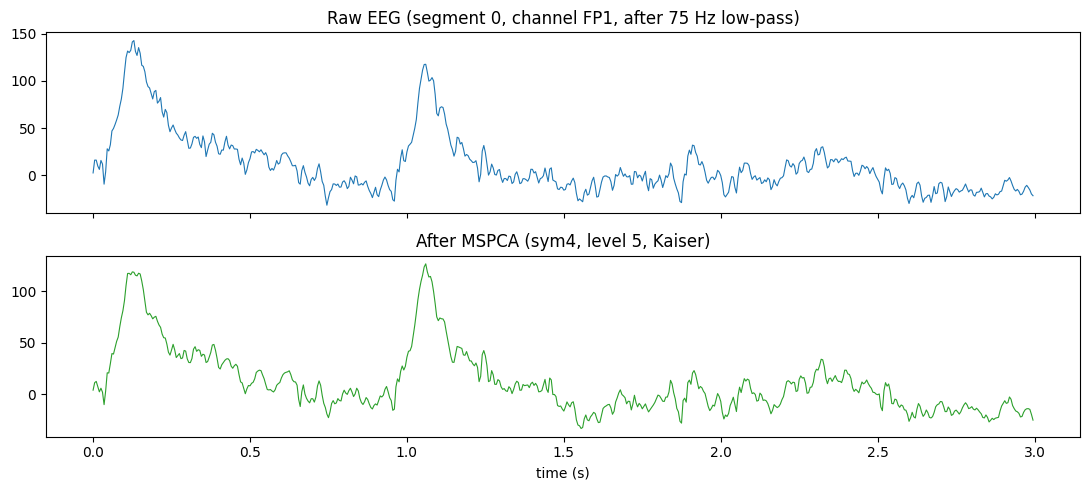

saved: X_mspca.npy, mspca_info.npz, mspca_config.json, results/mspca_example.png


cell 4 completed in 47.2 s
variables kept: X (raw), Y (denoised), y, subj, NPC


In [5]:
# cell 4: mspca denoising (symlets-4, 5 levels), test it, run it on all segments

import time
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt
from IPython.display import display, HTML
warnings.filterwarnings("ignore")
t0 = time.time()

# reuse the path from earlier cells, or fall back to the known folder
try:
    DATA_DIR = Path(DATA_DIR)
except NameError:
    DATA_DIR = Path("/content/seed_project/data")
PROJECT_DIR = DATA_DIR.parent
CACHE_DIR = PROJECT_DIR / "cache"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# load the segments from cache if the runtime was restarted
try:
    X; y; subj
except NameError:
    X = np.load(CACHE_DIR / "X_raw.npy")
    _m = np.load(CACHE_DIR / "meta.npz")
    y, subj = _m["y"], _m["subj"]


# helpers for headings, neat tables and spacing (output only)
def section(title):
    display(HTML(f"<h2 style='margin-top:40px;margin-bottom:8px;"
                 f"border-bottom:2px solid #888;padding-bottom:4px'>{title}</h2>"))

def gap(px=30):
    display(HTML(f"<div style='height:{px}px'></div>"))

def show(table, caption, fmt=None, index=False):
    try:
        sty = (table.style.format(fmt or {}, na_rep="-").set_caption(caption)
               .set_table_styles([
                   dict(selector="caption", props=[("caption-side", "top"), ("text-align", "left"),
                                                   ("font-size", "15px"), ("font-weight", "bold"),
                                                   ("padding", "0 0 8px 0")]),
                   dict(selector="th", props=[("padding", "7px 18px"), ("text-align", "center")]),
                   dict(selector="td", props=[("padding", "7px 18px"), ("text-align", "center")])]))
        if not index:
            sty = sty.hide(axis="index")
        display(sty)
    except Exception:
        display(table)
    gap()


print("X:", X.shape, X.dtype, "| y:", y.shape)
gap(10)

# settings
WAVELET, LEVEL, MODE = "sym4", 5, "periodization"
SCALES = ["A5", "D5", "D4", "D3", "D2", "D1"]   # order given by pywt.wavedec


# the mspca function
def mspca_denoise(seg, rule="kaiser", keep_all=False, wavelet=WAVELET, level=LEVEL, mode=MODE):
    """
    multiscale pca on one segment of shape (channels, samples)
    1) wavelet decompose every channel
    2) at each scale run pca across channels and keep the main components
    3) rebuild each scale and do the inverse wavelet transform
    rule 'kaiser' keeps components with eigenvalue above the mean eigenvalue
    rule 'var95' keeps components explaining 95% of the variance
    keep_all=True keeps everything (only used to test perfect reconstruction)
    returns the denoised segment and the number of components kept per scale
    """
    seg = np.asarray(seg, dtype=np.float64)
    coeffs = pywt.wavedec(seg, wavelet, level=level, mode=mode, axis=1)   # one array per scale
    new, kept = [], []
    for c in coeffs:
        Z = c.T                                   # rows = coefficients, columns = channels
        mu = Z.mean(axis=0)
        sd = Z.std(axis=0)
        sd[sd < 1e-12] = 1.0
        Zs = (Z - mu) / sd                        # standardise each channel
        cov = (Zs.T @ Zs) / max(len(Zs) - 1, 1)   # correlation between channels at this scale
        w, V = np.linalg.eigh(cov)
        order = np.argsort(w)[::-1]
        w, V = w[order], V[:, order]              # biggest eigenvalue first
        w = np.clip(w, 0, None)
        if keep_all:
            k = len(w)
        elif rule == "kaiser":
            k = max(1, int((w > w.mean()).sum()))
        elif rule == "var95":
            k = int(np.searchsorted(np.cumsum(w) / w.sum(), 0.95) + 1)
        else:
            raise ValueError(rule)
        Vk = V[:, :k]
        Zr = (Zs @ Vk) @ Vk.T                     # project on kept components and come back
        new.append((Zr * sd + mu).T)
        kept.append(k)
    rec = pywt.waverec(new, wavelet, mode=mode, axis=1)[:, :seg.shape[1]]
    return rec, kept


# 1. amplitude check for each subject (nothing is removed)
section("1) Amplitude check per subject")

rows = []
for s in np.unique(subj):
    Xi = X[subj == s]
    mx = np.abs(Xi).max(axis=(1, 2))
    rows.append(dict(Subject=int(s), Std=float(Xi.std()), Abs99_9=float(np.percentile(np.abs(Xi), 99.9)),
                     MaxAbs=float(mx.max()), Over500=int((mx > 500).sum()), Segments=len(Xi)))
amp_tbl = pd.DataFrame(rows)
amp_tbl.columns = ["Subject", "Std (uV)", "99.9th percentile |x| (uV)", "Max |x| (uV)",
                   "Segments over 500 uV", "Segments"]
show(amp_tbl, "Amplitude per subject (diagnostic only, nothing removed)",
     {"Std (uV)": "{:.1f}", "99.9th percentile |x| (uV)": "{:.1f}", "Max |x| (uV)": "{:.1f}"})


# 2. test a: keeping all components must give back the same signal
section("2) Test A: perfect reconstruction")

rng = np.random.default_rng(42)
errs = []
for i in rng.choice(len(X), 10, replace=False):
    s = X[i].astype(np.float64)
    r, _ = mspca_denoise(s, keep_all=True)
    errs.append(np.abs(r - s).max() / np.abs(s).max())

testA = pd.DataFrame({"Item": ["Max relative error over 10 real segments", "Result"],
                      "Value": [f"{max(errs):.2e}", "PASS" if max(errs) < 1e-8 else "FAIL"]})
show(testA, "Keep all components, output must equal input")


# 3. test b: fake signal where we know the clean version
section("3) Test B: synthetic SNR test")

fs, n = 200, 1024
t = np.arange(n) / fs
# 3 sources mixed into 62 channels, plus white noise
S = np.vstack([np.sin(2*np.pi*10*t),
               np.sin(2*np.pi*25*t) * (0.5 + 0.5*np.sin(2*np.pi*0.5*t)),
               np.sin(2*np.pi*(5 + 15*t/t[-1]) * t)])
A = rng.standard_normal((62, 3))
clean = A @ S
noise = rng.standard_normal(clean.shape) * clean.std() * 10**(-5/20)   # about 5 db noise
noisy = clean + noise
snr = lambda est: 10*np.log10((clean**2).mean() / ((est - clean)**2).mean())

rows = [["Noisy input", f"{snr(noisy):.2f}", "-"]]
for rule in ["kaiser", "var95"]:
    den, kept = mspca_denoise(noisy, rule=rule)
    rows.append([f"MSPCA ({rule})", f"{snr(den):.2f}", str(kept)])
testB = pd.DataFrame(rows, columns=["Signal", "SNR (dB)", f"PCs kept per scale {SCALES}"])
show(testB, "Higher SNR means less noise")
print("this only checks the code works, it says nothing about eeg accuracy")
gap()


# 4. test c: compare the two component rules on real data
section("4) Test C: component rules on 100 real segments")

samp = rng.choice(len(X), 100, replace=False)
tab = {}
for rule in ["kaiser", "var95"]:
    K, Ev = [], []
    for i in samp:
        s = X[i].astype(np.float64)
        r, k = mspca_denoise(s, rule=rule)
        K.append(k)
        Ev.append(((r - r.mean(1, keepdims=True))**2).sum() / ((s - s.mean(1, keepdims=True))**2).sum())
    tab[rule] = list(np.round(np.mean(K, axis=0), 1)) + [round(float(np.mean(Ev)), 4)]
testC = pd.DataFrame(tab, index=SCALES + ["Energy retained"]).T
testC.index.name = "Rule"
show(testC.reset_index(), "Average components kept per scale and energy retained",
     {c: "{:.1f}" for c in SCALES} | {"Energy retained": "{:.4f}"})


# 5. run mspca on all segments (kaiser rule)
section("5) Running MSPCA on all segments")
print(f"segments to process: {len(X)}")
gap(10)

Y = np.empty_like(X)
NPC = np.zeros((len(X), len(SCALES)), dtype=np.int16)
EN = np.zeros(len(X))
CR = np.zeros(len(X))
for i in range(len(X)):
    s = X[i].astype(np.float64)
    r, k = mspca_denoise(s, rule="kaiser")
    Y[i] = r.astype(np.float32)
    NPC[i] = k
    sc, rc = s - s.mean(1, keepdims=True), r - r.mean(1, keepdims=True)
    EN[i] = (rc**2).sum() / (sc**2).sum()                                       # energy kept
    CR[i] = ((sc*rc).sum(1) / (np.sqrt((sc**2).sum(1) * (rc**2).sum(1)) + 1e-12)).mean()   # raw vs denoised correlation
    if (i + 1) % 500 == 0:
        print(f"  processed {i + 1} / {len(X)}  ({time.time() - t0:.0f} s)")
gap(10)


# 6. check the denoised output
section("6) Validation")

val_tbl = pd.DataFrame({
    "Check": ["Y shape", "Y dtype", "Same shape as X", "NaN count", "Inf count",
              "Energy retained (mean)", "Energy retained (min)", "Energy retained (max)",
              "Correlation raw vs denoised (mean)", "Correlation raw vs denoised (min)"],
    "Value": [str(Y.shape), str(Y.dtype), str(Y.shape == X.shape), int(np.isnan(Y).sum()),
              int(np.isinf(Y).sum()), f"{EN.mean():.3f}", f"{EN.min():.3f}", f"{EN.max():.3f}",
              f"{CR.mean():.3f}", f"{CR.min():.3f}"]})
show(val_tbl, "Checks on the denoised data")

pc_tbl = pd.DataFrame({"Scale": SCALES,
                       "Min": [int(NPC[:, j].min()) for j in range(len(SCALES))],
                       "Mean": [NPC[:, j].mean() for j in range(len(SCALES))],
                       "Max": [int(NPC[:, j].max()) for j in range(len(SCALES))]})
show(pc_tbl, "Components kept per scale (out of 62)", {"Mean": "{:.1f}"})

subj_tbl = pd.DataFrame(dict(Subject=subj, Energy=EN, Corr=CR)).groupby("Subject").mean().reset_index()
subj_tbl.columns = ["Subject", "Energy retained", "Correlation"]
show(subj_tbl, "Average energy retained and correlation per subject",
     {"Energy retained": "{:.3f}", "Correlation": "{:.3f}"})


# 7. plot one example, then save
section("7) Example plot and saving")

i0 = 0
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
tt = np.arange(600) / fs
ax[0].plot(tt, X[i0, 0, :600], lw=0.8)
ax[0].set_title("Raw EEG (segment 0, channel FP1, after 75 Hz low-pass)")
ax[1].plot(tt, Y[i0, 0, :600], lw=0.8, color="tab:green")
ax[1].set_title("After MSPCA (sym4, level 5, Kaiser)")
ax[1].set_xlabel("time (s)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "mspca_example.png", dpi=120)
plt.show()
gap()

np.save(CACHE_DIR / "X_mspca.npy", Y)
np.savez(CACHE_DIR / "mspca_info.npz", npcs=NPC, energy=EN, corr=CR)
json.dump(dict(wavelet=WAVELET, level=LEVEL, mode=MODE, rule="kaiser", scales=SCALES),
          open(CACHE_DIR / "mspca_config.json", "w"), indent=2)

print("saved: X_mspca.npy, mspca_info.npz, mspca_config.json, results/mspca_example.png")
gap(10)
print(f"cell 4 completed in {time.time() - t0:.1f} s")
print("variables kept: X (raw), Y (denoised), y, subj, NPC")

denoised data: (1410, 62, 1024) | labels: (1410,)


signal: x[n] = 1.5 x[n-1] - 0.75 x[n-2] + noise, noise variance = 1


Quantity,True value,Estimated mean,Estimated std
a1,-1.500,-1.499,0.022
a2,0.750,0.749,0.023
noise variance (sigma^2),1.000,0.999,0.044


Item,Value
Order 15: mean of first two coefficients,[-1.498 0.748]
Order 15: mean |a[3..15]| (should be near 0),0.0034
PSD (order 15) vs true PSD: median relative error,1.5 %
Result,PASS


Item,Value
max |a_mcov - a_lstsq|,8.85e-09
sigma2 (mcov),6.0529
mean squared stacked residual,6.0529
Result,PASS


...

modified covariance does not guarantee stability, so a few poles at or over 1 is normal


segments: 1410 | channels: 62 | ar order: 15 | psd points: 40


  400 / 1410  (9 s)
  800 / 1410  (16 s)
  1200 / 1410  (21 s)


Check,Value
PSD shape,"(1410, 62, 40)"
NaN count,0
Inf count,0
sigma2 minimum,1.405e-02
PSD minimum,9.596e-03
PSD maximum,9.251e+10
F_full shape (62 x 40),"(1410, 2480)"
F_avg shape (channel average),"(1410, 40)"
Labels shape,"(1410,)"
log10 PSD range,-2.02 to 10.97


Subject,Mean log10 PSD,Std
1,1.38,0.34
2,1.22,0.27
3,1.38,0.13
4,1.67,0.24
5,1.89,1.31


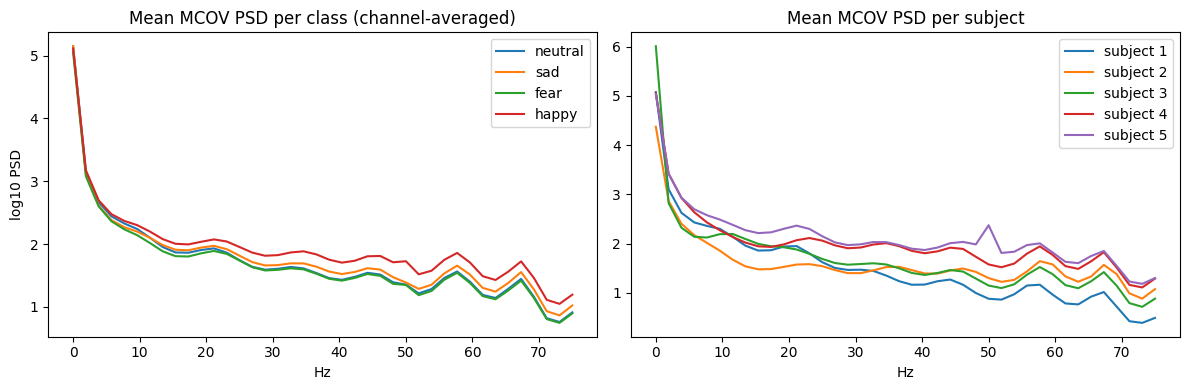

saved: F_full.npy, F_avg.npy, mcov_raw.npz, mcov_config.json, results/mcov_class_spectra.png


cell 5 completed in 25.1 s
variables kept: F_full, F_avg, PSD, y, subj, FREQS


In [6]:
# cell 5: mcov features (modified covariance, ar order 15, 40 psd points)

import time
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from scipy import signal
import matplotlib.pyplot as plt
from IPython.display import display, HTML
warnings.filterwarnings("ignore")
t0 = time.time()

# reuse the path from earlier cells, or fall back to the known folder
try:
    DATA_DIR = Path(DATA_DIR)
except NameError:
    DATA_DIR = Path("/content/seed_project/data")
PROJECT_DIR = DATA_DIR.parent
CACHE_DIR = PROJECT_DIR / "cache"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# load the denoised data from cache if the runtime was restarted
try:
    Y; y; subj
except NameError:
    Y = np.load(CACHE_DIR / "X_mspca.npy")
    _m = np.load(CACHE_DIR / "meta.npz")
    y, subj = _m["y"], _m["subj"]
try:
    CLASS_NAMES
except NameError:
    CLASS_NAMES = ["neutral", "sad", "fear", "happy"]


# helpers for headings, neat tables and spacing (output only)
def section(title):
    display(HTML(f"<h2 style='margin-top:40px;margin-bottom:8px;"
                 f"border-bottom:2px solid #888;padding-bottom:4px'>{title}</h2>"))

def gap(px=30):
    display(HTML(f"<div style='height:{px}px'></div>"))

def show(table, caption, fmt=None, index=False):
    try:
        sty = (table.style.format(fmt or {}, na_rep="-").set_caption(caption)
               .set_table_styles([
                   dict(selector="caption", props=[("caption-side", "top"), ("text-align", "left"),
                                                   ("font-size", "15px"), ("font-weight", "bold"),
                                                   ("padding", "0 0 8px 0")]),
                   dict(selector="th", props=[("padding", "7px 18px"), ("text-align", "center")]),
                   dict(selector="td", props=[("padding", "7px 18px"), ("text-align", "center")])]))
        if not index:
            sty = sty.hide(axis="index")
        display(sty)
    except Exception:
        display(table)
    gap()


print("denoised data:", Y.shape, "| labels:", y.shape)
gap(10)

# settings
FS, ORDER, N_PSD, F_MAX = 200, 15, 40, 75.0
FREQS = np.linspace(0.0, F_MAX, N_PSD)   # 40 frequency points between 0 and 75 hz (our choice)


# mcov function: finds the ar coefficients of a signal
def mcov_ar(x, order=ORDER):
    """
    modified covariance ar estimation (paper eqs 1-9), works on many channels at once
    x : (..., N) signal
    returns a (..., order) and sigma2 (...)
    model is x[n] + sum a[m] x[n-m] = e[n]
    the covariance terms use both forward and backward prediction (eq 8)
    we solve C a = -c and sigma2 is the prediction error power
    """
    x = np.asarray(x, dtype=np.float64)
    N, k = x.shape[-1], order
    W = sliding_window_view(x, k + 1, axis=-1)            # every window of k+1 samples
    G = np.einsum("...nj,...nm->...jm", W, W)             # backward sum
    Cfull = (G + G[..., ::-1, ::-1]) / (2.0 * (N - k))    # forward sum is the same with indices reversed
    C, c = Cfull[..., 1:, 1:], Cfull[..., 1:, 0]
    try:
        a = -np.linalg.solve(C, c[..., None])[..., 0]
    except np.linalg.LinAlgError:
        a = -np.einsum("...ij,...j->...i", np.linalg.pinv(C), c)
    sigma2 = Cfull[..., 0, 0] + np.einsum("...m,...m->...", a, Cfull[..., 0, 1:])
    return a, sigma2


# psd function: turns the ar coefficients into power at each frequency
def mcov_psd(a, sigma2, freqs=FREQS, fs=FS):
    """psd(f) = sigma2 / |1 + sum a(m) exp(-j 2 pi f m)|^2  (eq 10)"""
    m = np.arange(1, a.shape[-1] + 1)
    E = np.exp(-2j * np.pi * np.outer(np.asarray(freqs) / fs, m))
    A = 1.0 + a @ E.T
    return sigma2[..., None] / (np.abs(A) ** 2)


# 1. test a: a signal whose ar coefficients we already know
section("1) Test A: known AR(2) process")
print("signal: x[n] = 1.5 x[n-1] - 0.75 x[n-2] + noise, noise variance = 1")
gap(10)

rng = np.random.default_rng(42)
true_a = np.array([-1.5, 0.75])
est2, est15, s2s = [], [], []
for _ in range(200):
    e = rng.standard_normal(1024 + 500)
    xr = signal.lfilter([1.0], [1.0, *true_a], e)[500:]
    a2, s2 = mcov_ar(xr, order=2)
    a15, _ = mcov_ar(xr, order=15)
    est2.append(a2); est15.append(a15); s2s.append(s2)
est2, est15 = np.array(est2), np.array(est15)

# compare the estimated psd with the true psd
w_true = true_a @ np.exp(-2j*np.pi*np.outer(FREQS/FS, [1, 2])).T
psd_true = 1.0 / np.abs(1 + w_true) ** 2
psd_est = np.mean([mcov_psd(a, np.array(1.0)) for a in est15], axis=0)
psd_err = 100 * np.median(np.abs(psd_est / psd_true - 1))

testA = pd.DataFrame({
    "Quantity": ["a1", "a2", "noise variance (sigma^2)"],
    "True value": [f"{true_a[0]:.3f}", f"{true_a[1]:.3f}", "1.000"],
    "Estimated mean": [f"{est2.mean(0)[0]:.3f}", f"{est2.mean(0)[1]:.3f}", f"{np.mean(s2s):.3f}"],
    "Estimated std": [f"{est2.std(0)[0]:.3f}", f"{est2.std(0)[1]:.3f}", f"{np.std(s2s):.3f}"]})
show(testA, "Order 2 fit over 200 random signals")

testA2 = pd.DataFrame({
    "Item": ["Order 15: mean of first two coefficients",
             "Order 15: mean |a[3..15]| (should be near 0)",
             "PSD (order 15) vs true PSD: median relative error",
             "Result"],
    "Value": [str(est15.mean(0)[:2].round(3)), f"{np.abs(est15.mean(0)[2:]).mean():.4f}",
              f"{psd_err:.1f} %",
              "PASS" if (np.abs(est2.mean(0) - true_a).max() < 0.02) else "CHECK: coefficients off"]})
show(testA2, "Order 15 fit on the same signals")


# 2. test b: compare with an independent least squares solution
section("2) Test B: match with independent least squares")

xr = Y[0, 0].astype(np.float64)
N, k = len(xr), ORDER
Wd = sliding_window_view(xr, k + 1)                          # each row is x[n..n+k]
Fwd_reg = Wd[:, :k][:, ::-1]; Fwd_tgt = Wd[:, k]             # forward: x[n] from x[n-1..n-k]
Bwd_reg = Wd[:, 1:];          Bwd_tgt = Wd[:, 0]             # backward: x[n] from x[n+1..n+k]
A_ls = np.vstack([Fwd_reg, Bwd_reg])
b_ls = np.concatenate([Fwd_tgt, Bwd_tgt])
a_ls = np.linalg.lstsq(A_ls, -b_ls, rcond=None)[0]
a_m, s2_m = mcov_ar(xr)
res = A_ls @ a_ls + b_ls

diff_b = np.abs(a_m - a_ls).max()
testB = pd.DataFrame({
    "Item": ["max |a_mcov - a_lstsq|", "sigma2 (mcov)", "mean squared stacked residual", "Result"],
    "Value": [f"{diff_b:.2e}", f"{s2_m:.4f}", f"{(res ** 2).mean():.4f}",
              "PASS" if diff_b < 1e-6 * max(1, np.abs(a_ls).max()) else "CHECK: mismatch"]})
show(testB, "mcov_ar against least squares on stacked forward and backward prediction")


# 3. test c: all channels at once must equal one channel at a time
section("3) Test C: batch equals per-channel loop")

a_b, s_b = mcov_ar(Y[0].astype(np.float64))
d = max(np.abs(a_b[ch] - mcov_ar(Y[0, ch].astype(np.float64))[0]).max() for ch in (0, 30, 61))
testC = pd.DataFrame({"Item": ["max difference (channels 0, 30, 61)", "Result"],
                      "Value": [f"{d:.2e}", "PASS" if d < 1e-8 else "CHECK"]})
show(testC, "Batch result against loop result")


# 4. test d: are the fitted ar models stable?
section("4) Test D: ar stability")

idx = rng.choice(len(Y), 300, replace=False)
chs = rng.integers(0, 62, 300)
pm = np.array([np.abs(np.roots(np.r_[1.0, mcov_ar(Y[i, c].astype(np.float64))[0]])).max()
               for i, c in zip(idx, chs)])
testD = pd.DataFrame({"Item": ["median of largest |pole|", "maximum of largest |pole|",
                               "fraction of fits with |pole| >= 1"],
                      "Value": [f"{np.median(pm):.4f}", f"{pm.max():.4f}", f"{(pm >= 1).mean():.3f}"]})
show(testD, "300 random channel-segments (poles should be inside the unit circle)")
print("modified covariance does not guarantee stability, so a few poles at or over 1 is normal")
gap()


# 5. extract mcov features from every segment
section("5) Extracting MCOV features")
print(f"segments: {len(Y)} | channels: 62 | ar order: {ORDER} | psd points: {N_PSD}")
gap(10)

n_seg = len(Y)
PSD = np.empty((n_seg, 62, N_PSD))
SIG2 = np.empty((n_seg, 62))
AR = np.empty((n_seg, 62, ORDER), dtype=np.float32)
for i in range(n_seg):
    a, s2 = mcov_ar(Y[i].astype(np.float64))
    PSD[i] = mcov_psd(a, s2)
    SIG2[i] = s2
    AR[i] = a
    if (i + 1) % 400 == 0:
        print(f"  {i + 1} / {n_seg}  ({time.time() - t0:.0f} s)")
gap(10)


# 6. check the features
section("6) Feature validation")

assert SIG2.min() > 0 and PSD.min() > 0, "non-positive variance/PSD found"
LOGPSD = np.log10(PSD)
F_full = LOGPSD.reshape(n_seg, -1)            # 62 x 40 = 2480 features (main set)
F_avg = np.log10(PSD.mean(axis=1))            # 40 features, psd averaged over channels
assert len(F_full) == len(F_avg) == len(y) == len(subj), "feature/label misalignment"

feat_tbl = pd.DataFrame({
    "Check": ["PSD shape", "NaN count", "Inf count", "sigma2 minimum", "PSD minimum", "PSD maximum",
              "F_full shape (62 x 40)", "F_avg shape (channel average)", "Labels shape",
              "log10 PSD range"],
    "Value": [str(PSD.shape), int(np.isnan(PSD).sum()), int(np.isinf(PSD).sum()),
              f"{SIG2.min():.3e}", f"{PSD.min():.3e}", f"{PSD.max():.3e}",
              str(F_full.shape), str(F_avg.shape), str(y.shape),
              f"{LOGPSD.min():.2f} to {LOGPSD.max():.2f}"]})
show(feat_tbl, "Checks on the extracted features")

# power level differs between subjects
lvl = (pd.DataFrame({"Subject": subj, "lvl": LOGPSD.mean(axis=(1, 2))})
       .groupby("Subject")["lvl"].agg(["mean", "std"]).reset_index())
lvl.columns = ["Subject", "Mean log10 PSD", "Std"]
show(lvl, "Mean log10 PSD per subject (shows power level differences between subjects)",
     {"Mean log10 PSD": "{:.2f}", "Std": "{:.2f}"})


# 7. plot the average spectra
section("7) Average spectra")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c, nm in enumerate(CLASS_NAMES):
    ax[0].plot(FREQS, F_avg[y == c].mean(axis=0), label=nm)
ax[0].set_title("Mean MCOV PSD per class (channel-averaged)")
ax[0].set_xlabel("Hz")
ax[0].set_ylabel("log10 PSD")
ax[0].legend()
for s in np.unique(subj):
    ax[1].plot(FREQS, F_avg[subj == s].mean(axis=0), label="subject %d" % s)
ax[1].set_title("Mean MCOV PSD per subject")
ax[1].set_xlabel("Hz")
ax[1].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "mcov_class_spectra.png", dpi=120)
plt.show()
gap()


# 8. save for the next cells
section("8) Saving")

np.save(CACHE_DIR / "F_full.npy", F_full)
np.save(CACHE_DIR / "F_avg.npy", F_avg)
np.savez(CACHE_DIR / "mcov_raw.npz", PSD=PSD, SIG2=SIG2, AR=AR, freqs=FREQS)
json.dump(dict(order=ORDER, n_psd=N_PSD, fmax=F_MAX, fs=FS, freqs=FREQS.tolist(),
               features="F_full=log10 PSD (62x40), F_avg=log10 of channel-mean PSD (40)"),
          open(CACHE_DIR / "mcov_config.json", "w"), indent=2)

print("saved: F_full.npy, F_avg.npy, mcov_raw.npz, mcov_config.json, results/mcov_class_spectra.png")
gap(10)
print(f"cell 5 completed in {time.time() - t0:.1f} s")
print("variables kept: F_full, F_avg, PSD, y, subj, FREQS")

In [13]:
# cell 6: mcov check + paper style 10-fold cv (decision tree, random forest, svm, bagging+rf)

import time
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from IPython.display import display, HTML
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer, label_binarize
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, roc_auc_score
warnings.filterwarnings("ignore")
t_cell = time.time()

# reuse the path from earlier cells, or fall back to the known folder
try:
    DATA_DIR = Path(DATA_DIR)
except NameError:
    DATA_DIR = Path("/content/seed_project/data")
PROJECT_DIR = DATA_DIR.parent
CACHE_DIR = PROJECT_DIR / "cache"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"
for d in (RESULTS_DIR, MODELS_DIR):
    d.mkdir(exist_ok=True)

# load features from cache if the runtime was restarted
try:
    F_full; F_avg; y; subj
except NameError:
    F_full = np.load(CACHE_DIR / "F_full.npy")
    F_avg = np.load(CACHE_DIR / "F_avg.npy")
    _m = np.load(CACHE_DIR / "meta.npz")
    y, subj = _m["y"], _m["subj"]
try:
    CLASS_NAMES
except NameError:
    CLASS_NAMES = ["neutral", "sad", "fear", "happy"]
SEED = 42


# helpers for headings, neat tables and spacing (output only)
def section(title):
    display(HTML(f"<h2 style='margin-top:40px;margin-bottom:8px;"
                 f"border-bottom:2px solid #888;padding-bottom:4px'>{title}</h2>"))

def gap(px=30):
    display(HTML(f"<div style='height:{px}px'></div>"))

def show(table, caption, fmt=None, index=False):
    try:
        sty = (table.style.format(fmt or {}, na_rep="-").set_caption(caption)
               .set_table_styles([
                   dict(selector="caption", props=[("caption-side", "top"), ("text-align", "left"),
                                                   ("font-size", "15px"), ("font-weight", "bold"),
                                                   ("padding", "0 0 8px 0")]),
                   dict(selector="th", props=[("padding", "7px 18px"), ("text-align", "center")]),
                   dict(selector="td", props=[("padding", "7px 18px"), ("text-align", "center")])]))
        if not index:
            sty = sty.hide(axis="index")
        display(sty)
    except Exception:
        display(table)
    gap()


data_tbl = pd.DataFrame({
    "Item": ["F_full (62 channels x 40 points)", "F_avg (channel average, 40 points)", "Labels", "Classes"],
    "Value": [str(F_full.shape), str(F_avg.shape), str(y.shape), str(list(np.unique(y)))]})
show(data_tbl, "Data loaded for this cell")


# 1. check mcov_ar again against an independent least squares solution
section("1) Test B: mcov_ar against least squares")

try:
    mcov_ar
    Yd = Y if "Y" in globals() else np.load(CACHE_DIR / "X_mspca.npy")
    k = 15
    worst_a, worst_s = 0.0, 0.0
    test_rows = []
    for (i, ch) in [(0, 0), (10, 30), (500, 61)]:
        xr = Yd[i, ch].astype(np.float64)
        Wd = sliding_window_view(xr, k + 1)              # row s = x[s..s+k]
        Fr, Ft = Wd[:, :k][:, ::-1], Wd[:, k]            # forward: x[n] from x[n-1..n-k]
        Br, Bt = Wd[:, 1:], Wd[:, 0]                     # backward: x[n] from x[n+1..n+k]
        A_ls, b_ls = np.vstack([Fr, Br]), np.concatenate([Ft, Bt])
        a_ls = np.linalg.lstsq(A_ls, -b_ls, rcond=None)[0]
        a_m, s2_m = mcov_ar(xr)
        s2_ls = ((A_ls @ a_ls + b_ls) ** 2).mean()
        ra = np.abs(a_m - a_ls).max() / max(1.0, np.abs(a_ls).max())
        rs = abs(s2_m - s2_ls) / s2_ls
        worst_a, worst_s = max(worst_a, ra), max(worst_s, rs)
        test_rows.append([i, ch, f"{ra:.2e}", f"{s2_m:.4f}", f"{s2_ls:.4f}"])
    ok = worst_a < 1e-5 and worst_s < 1e-6
    testB = pd.DataFrame(test_rows, columns=["Segment", "Channel", "Max relative |a diff|",
                                             "sigma2 (mcov)", "sigma2 (lstsq)"])
    show(testB, "mcov_ar compared with least squares")
    print("result :", "PASS, mcov_ar matches the independent solution" if ok else "FAIL")
    gap(10)
    # stop here if the check fails
    assert ok, "mcov_ar does not match the independent least squares solution"
except NameError:
    print("mcov_ar is not in memory (runtime restarted?), skipping this check. rerun cell 5 to enable it.")
    gap()


# 2. models
def clip5(Z):                       # kept at top level so the pipeline can be saved later
    return np.clip(Z, -5.0, 5.0)

def make_dt():
    return DecisionTreeClassifier(random_state=SEED)

def make_rf():
    return RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)

def make_svm():
    return make_pipeline(StandardScaler(), FunctionTransformer(clip5),
                         SVC(kernel="rbf", C=100, gamma="scale", random_state=SEED))

def make_bagrf(n_trees):
    return BaggingClassifier(RandomForestClassifier(n_estimators=n_trees, n_jobs=1, random_state=SEED),
                             n_estimators=10, max_samples=1.0, bootstrap=True, n_jobs=-1, random_state=SEED)

# stratified 10 fold split, same folds are used for every model
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = list(skf.split(F_full, y))


# 3. choose the bagging+rf size so the run fits in the time limit
section("2) Choosing the Bagging+RF size")
print("time limit for 10 folds on the 2480 feature set: about 120 s")
gap(10)

tr0, te0 = folds[0]
tb = time.time()
make_bagrf(10).fit(F_full[tr0], y[tr0])      # time one fold with 10 trees per bag
t10 = time.time() - tb

BAG_TREES = 10
cal_rows = []
for cand in [100, 50, 30, 20, 10]:
    est = t10 * (cand / 10) * 10             # estimate for 10 folds
    cal_rows.append([cand, est, "fits" if est <= 120 else "too slow"])
    if est <= 120:
        BAG_TREES = cand
        break
cal_tbl = pd.DataFrame(cal_rows, columns=["RF trees per bag", "Estimated time (s)", "Fits in limit?"])
show(cal_tbl, "Estimated time for 10 folds", {"Estimated time (s)": "{:.0f}"})

print(f"chosen : bagging (10 bags) of random forest with {BAG_TREES} trees each"
      + ("" if BAG_TREES == 100 else "  (reduced from the paper's 100 for colab time)"))
gap()


# 4. function that runs 10 fold cv for one model
def run_cv(name, make_model, F):
    oof_pred = np.empty(len(y), dtype=int)
    oof_score = np.zeros((len(y), 4))
    fold_acc = []
    t = time.time()
    for tr, te in folds:
        m = make_model().fit(F[tr], y[tr])
        p = m.predict(F[te])
        oof_pred[te] = p
        oof_score[te] = m.predict_proba(F[te]) if hasattr(m, "predict_proba") else m.decision_function(F[te])
        fold_acc.append(accuracy_score(y[te], p))
    Yb = label_binarize(y, classes=[0, 1, 2, 3])
    return dict(model=name, acc_mean=np.mean(fold_acc), acc_std=np.std(fold_acc),
                acc_pooled=accuracy_score(y, oof_pred), f1_macro=f1_score(y, oof_pred, average="macro"),
                kappa=cohen_kappa_score(y, oof_pred), auc_ovr=roc_auc_score(Yb, oof_score, average="macro"),
                seconds=time.time() - t), oof_pred, oof_score

makers = {"DecisionTree": make_dt, "RandomForest": make_rf, "SVM": make_svm,
          "Bagging+RF": lambda: make_bagrf(BAG_TREES)}
feature_sets = {"F_full (62x40=2480)": F_full, "F_avg (40, paper-literal)": F_avg}


# 5. run all models on both feature sets
section("3) Stratified 10-fold cross validation")
print("this is the paper's protocol. segments are split randomly, so it is leaky (see cell 7)")
gap(10)

rows, OOF = [], {}
for fs_name, F in feature_sets.items():
    for mname, mk in makers.items():
        res, pred, score = run_cv(mname, mk, F)
        res["features"] = fs_name
        rows.append(res)
        OOF[(fs_name, mname)] = (pred, score)
        print(f"  done: {fs_name:<28}{mname:<14}acc {res['acc_mean']:.4f}  ({res['seconds']:.0f} s)")
gap(10)


# 6. results tables
section("4) Results")

tab = pd.DataFrame(rows)[["features", "model", "acc_mean", "acc_std", "acc_pooled",
                          "f1_macro", "kappa", "auc_ovr", "seconds"]]

nice_cols = {"model": "Model", "acc_mean": "Accuracy (mean of folds)", "acc_std": "Accuracy std",
             "acc_pooled": "Accuracy (all folds pooled)", "f1_macro": "Macro F1", "kappa": "Kappa",
             "auc_ovr": "Macro AUC", "seconds": "Time (s)"}
fmt = {"Accuracy (mean of folds)": "{:.4f}", "Accuracy std": "{:.4f}", "Accuracy (all folds pooled)": "{:.4f}",
       "Macro F1": "{:.4f}", "Kappa": "{:.4f}", "Macro AUC": "{:.4f}", "Time (s)": "{:.0f}"}

for fs_name in feature_sets:
    part = tab[tab.features == fs_name].drop(columns="features").rename(columns=nice_cols)
    show(part, f"Feature set: {fs_name}", fmt)

print("chance level for 4 balanced classes = 0.25")
print("paper (3 class SEED) reported 0.996 for Bagging+RF, so it is not comparable here")
gap()


# 7. save for the next cells
section("5) Saving")

tab.to_csv(RESULTS_DIR / "cv10_results.csv", index=False)
np.savez(CACHE_DIR / "cv10_oof.npz", y=y, subj=subj,
         **{f"{fs.split()[0]}__{m}__pred": v[0] for (fs, m), v in OOF.items()},
         **{f"{fs.split()[0]}__{m}__score": v[1] for (fs, m), v in OOF.items()})
json.dump(dict(bag_rf_trees=BAG_TREES, bags=10, rf_trees=100, svm="rbf C=100 (paper: Puk C=100)",
               folds=10, seed=SEED),
          open(CACHE_DIR / "model_config.json", "w"), indent=2)

print("saved: results/cv10_results.csv, cache/cv10_oof.npz, cache/model_config.json")
gap(10)
print(f"cell 6 completed in {time.time() - t_cell:.0f} s")
print("variables kept: tab, OOF, folds, makers, BAG_TREES, F_full, F_avg, y, subj")

Item,Value
F_full (62 channels x 40 points),"(1410, 2480)"
"F_avg (channel average, 40 points)","(1410, 40)"
Labels,"(1410,)"
Classes,"[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]"


Segment,Channel,Max relative |a diff|,sigma2 (mcov),sigma2 (lstsq)
0,0,8.31e-10,6.0529,6.0529
10,30,1.10e-09,1.6518,1.6518
500,61,2.45e-10,2.5725,2.5725


result : PASS, mcov_ar matches the independent solution


time limit for 10 folds on the 2480 feature set: about 120 s


RF trees per bag,Estimated time (s),Fits in limit?
100,1403,too slow
50,701,too slow
30,421,too slow
20,281,too slow
10,140,too slow


...

Model,Accuracy (mean of folds),Accuracy std,Accuracy (all folds pooled),Macro F1,Kappa,Macro AUC,Time (s)
DecisionTree,0.4596,0.0553,0.4596,0.4600,0.2795,0.6401,63
RandomForest,0.6667,0.0369,0.6667,0.6672,0.5555,0.8719,58
SVM,0.7284,0.0298,0.7284,0.7293,0.6377,0.8940,36
Bagging+RF,0.6411,0.0284,0.6411,0.6417,0.5214,0.8531,39


Model,Accuracy (mean of folds),Accuracy std,Accuracy (all folds pooled),Macro F1,Kappa,Macro AUC,Time (s)
DecisionTree,0.3652,0.0345,0.3652,0.3658,0.1534,0.5769,1
RandomForest,0.4787,0.0359,0.4787,0.4790,0.3048,0.7273,9
SVM,0.4957,0.0420,0.4957,0.4951,0.3269,0.7363,4
Bagging+RF,0.4525,0.0318,0.4525,0.4519,0.2699,0.7261,7


chance level for 4 balanced classes = 0.25
paper (3 class SEED) reported 0.996 for Bagging+RF, so it is not comparable here


saved: results/cv10_results.csv, cache/cv10_oof.npz, cache/model_config.json


cell 6 completed in 231 s
variables kept: tab, OOF, folds, makers, BAG_TREES, F_full, F_avg, y, subj


In [14]:
# cell 7: subject-wise test (loso), trial-grouped cv, and subject identification check

import time
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, HTML
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer, label_binarize
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, roc_auc_score
warnings.filterwarnings("ignore")
t_cell = time.time()

# reuse the path from earlier cells, or fall back to the known folder
try:
    DATA_DIR = Path(DATA_DIR)
except NameError:
    DATA_DIR = Path("/content/seed_project/data")
PROJECT_DIR = DATA_DIR.parent
CACHE_DIR = PROJECT_DIR / "cache"
RESULTS_DIR = PROJECT_DIR / "results"

# load labels, features and settings saved by the earlier cells
_m = np.load(CACHE_DIR / "meta.npz")
y, subj, trial = _m["y"], _m["subj"], _m["trial"]
F_full = np.load(CACHE_DIR / "F_full.npy")
F_avg = np.load(CACHE_DIR / "F_avg.npy")
cfg = json.load(open(CACHE_DIR / "model_config.json"))
BAG_TREES, SEED = cfg["bag_rf_trees"], cfg["seed"]
CLASS_NAMES = ["neutral", "sad", "fear", "happy"]


# helpers for headings, neat tables and spacing (output only)
def section(title):
    display(HTML(f"<h2 style='margin-top:40px;margin-bottom:8px;"
                 f"border-bottom:2px solid #888;padding-bottom:4px'>{title}</h2>"))

def gap(px=30):
    display(HTML(f"<div style='height:{px}px'></div>"))

def show(table, caption, fmt=None, index=False):
    try:
        sty = (table.style.format(fmt or {}, na_rep="-").set_caption(caption)
               .set_table_styles([
                   dict(selector="caption", props=[("caption-side", "top"), ("text-align", "left"),
                                                   ("font-size", "15px"), ("font-weight", "bold"),
                                                   ("padding", "0 0 8px 0")]),
                   dict(selector="th", props=[("padding", "7px 18px"), ("text-align", "center")]),
                   dict(selector="td", props=[("padding", "7px 18px"), ("text-align", "center")])]))
        if not index:
            sty = sty.hide(axis="index")
        display(sty)
    except Exception:
        display(table)
    gap()


data_tbl = pd.DataFrame({
    "Item": ["F_full shape", "Subjects", "Bagging+RF trees per bag"],
    "Value": [str(F_full.shape), str(list(np.unique(subj))), BAG_TREES]})
show(data_tbl, "Data loaded for this cell")


# models (same as cell 6)
def clip5(Z):
    return np.clip(Z, -5.0, 5.0)

makers = {
    "DecisionTree": lambda: DecisionTreeClassifier(random_state=SEED),
    "RandomForest": lambda: RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED),
    "SVM": lambda: make_pipeline(StandardScaler(), FunctionTransformer(clip5),
                                 SVC(kernel="rbf", C=100, gamma="scale", random_state=SEED)),
    "Bagging+RF": lambda: BaggingClassifier(
        RandomForestClassifier(n_estimators=BAG_TREES, n_jobs=1, random_state=SEED),
        n_estimators=10, bootstrap=True, n_jobs=-1, random_state=SEED),
}


# 1. build the splits and check that nothing leaks between train and test
section("1) Split checks")

groups = subj * 100 + trial   # one group = one clip of one subject
folds_loso = [(np.where(subj != s)[0], np.where(subj == s)[0]) for s in np.unique(subj)]
folds_grp = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(F_full, y, groups))

# train and test must not share a subject (loso) or a clip (grouped)
for tr, te in folds_loso:
    assert set(subj[tr]).isdisjoint(set(subj[te])), "subject leakage in LOSO"
for tr, te in folds_grp:
    assert set(groups[tr]).isdisjoint(set(groups[te])), "trial leakage in grouped CV"
print("all split checks passed, no subject or clip appears in both train and test")
gap(10)

loso_sz = pd.DataFrame({"Held-out subject": list(np.unique(subj)),
                        "Test instances": [len(te) for _, te in folds_loso]})
show(loso_sz, "Leave-one-subject-out: test size per fold")

grp_sz = pd.DataFrame([np.bincount(y[te], minlength=4) for _, te in folds_grp], columns=CLASS_NAMES)
grp_sz.insert(0, "Fold", range(1, len(grp_sz) + 1))
grp_sz["Total"] = grp_sz[CLASS_NAMES].sum(axis=1)
show(grp_sz, f"Trial-grouped 5-fold: test instances per class ({len(np.unique(groups))} clips in total)")


# 2. function that runs one cv scheme for one model
def run(folds, F, make_model):
    pred = np.empty(len(y), dtype=int)
    score = np.zeros((len(y), 4))
    fold_acc = []
    t = time.time()
    for tr, te in folds:
        m = make_model().fit(F[tr], y[tr])
        pred[te] = m.predict(F[te])
        score[te] = m.predict_proba(F[te]) if hasattr(m, "predict_proba") else m.decision_function(F[te])
        fold_acc.append(accuracy_score(y[te], pred[te]))
    auc = roc_auc_score(label_binarize(y, classes=[0, 1, 2, 3]), score, average="macro")
    return dict(acc_mean=np.mean(fold_acc), acc_std=np.std(fold_acc),
                f1_macro=f1_score(y, pred, average="macro"),
                kappa=cohen_kappa_score(y, pred), auc_ovr=auc,
                seconds=time.time() - t), pred, score, fold_acc

rows, OOF, PER_SUBJECT = [], {}, {}

RES_COLS = {"model": "Model", "acc_mean": "Accuracy (mean of folds)", "acc_std": "Accuracy std",
            "f1_macro": "Macro F1", "kappa": "Kappa", "auc_ovr": "Macro AUC", "seconds": "Time (s)"}
RES_FMT = {"Accuracy (mean of folds)": "{:.4f}", "Accuracy std": "{:.4f}", "Macro F1": "{:.4f}",
           "Kappa": "{:.4f}", "Macro AUC": "{:.4f}", "Time (s)": "{:.0f}"}

def go(scheme, folds, F, models, label_suffix=""):
    start = len(rows)
    for mname in models:
        res, pred, score, fa = run(folds, F, makers[mname])
        res.update(scheme=scheme, model=mname + label_suffix)
        rows.append(res)
        OOF[(scheme, mname + label_suffix)] = (pred, score)
        if scheme.startswith("LOSO"):
            PER_SUBJECT[mname + label_suffix] = fa
        print(f"  done: {mname + label_suffix:<20}acc {res['acc_mean']:.4f}  ({res['seconds']:.0f} s)")
    gap(10)
    part = pd.DataFrame(rows[start:])[list(RES_COLS)].rename(columns=RES_COLS)
    show(part, f"Scheme: {scheme}", RES_FMT)


# 3. leave one subject out: train on 4 subjects, test on the 5th
section("2) Leave-one-subject-out (LOSO)")
print("train on 4 subjects, test on the unseen one")
gap(10)
go("LOSO", folds_loso, F_full, ["DecisionTree", "RandomForest", "SVM", "Bagging+RF"])


# 4. trial grouped cv: whole clips are held out
section("3) Trial-grouped 5-fold")
print("whole clips are held out, but the same subjects are in train and test")
gap(10)
go("TrialGrouped-5fold", folds_grp, F_full, ["DecisionTree", "RandomForest", "SVM", "Bagging+RF"])


# 5. loso again, after standardising the features of each subject separately
section("4) LOSO with per-subject standardisation (SVM only)")
print("each subject's features are scaled with that subject's own mean and std (labels are not used)")
print("note: this uses the unlabelled test subject's data to compute the mean and std")
gap(10)

Fz = F_full.copy()
for s in np.unique(subj):
    idx = subj == s
    Fz[idx] = (F_full[idx] - F_full[idx].mean(0)) / (F_full[idx].std(0) + 1e-9)
go("LOSO+subject-zscore", folds_loso, Fz, ["SVM"], label_suffix="(subj-z)")


# 6. loso accuracy for each held out subject
section("5) LOSO accuracy for each held-out subject")

ps_tbl = pd.DataFrame(PER_SUBJECT, index=[int(s) for s in np.unique(subj)])
ps_tbl.index.name = "Held-out subject"
show(ps_tbl.reset_index(), "Accuracy on each unseen subject", {c: "{:.3f}" for c in ps_tbl.columns})


# 7. can the features tell which subject a segment came from?
section("6) Can the features identify the subject?")
print("random forest on the 40 feature set, 5-fold, target = subject id (chance = 0.20)")
gap(10)

ps = np.empty(len(y), dtype=int)
for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(F_avg, subj):
    ps[te] = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED).fit(F_avg[tr], subj[tr]).predict(F_avg[te])

id_tbl = pd.DataFrame({"Item": ["Subject identification accuracy", "Chance level"],
                       "Value": [f"{accuracy_score(subj, ps):.3f}", "0.200"]})
show(id_tbl, "Subject identification")


# 8. compare with the random 10 fold result from cell 6
section("7) Accuracy by evaluation scheme (2480 feature set)")

t6 = pd.read_csv(RESULTS_DIR / "cv10_results.csv")
t6 = t6[t6.features.str.startswith("F_full")][["model", "acc_mean"]].rename(
    columns={"acc_mean": "Random10fold (paper protocol)"})
cur = pd.DataFrame(rows).pivot(index="model", columns="scheme", values="acc_mean")
cmp_ = t6.set_index("model").join(cur, how="outer")[
    ["Random10fold (paper protocol)", "TrialGrouped-5fold", "LOSO", "LOSO+subject-zscore"]]
cmp_.index.name = "Model"

show(cmp_.reset_index(), "Accuracy under each evaluation scheme", {c: "{:.4f}" for c in cmp_.columns})
print("chance = 0.25")
print("a drop from the first column to the later ones shows how much the paper's protocol is inflated")
gap()


# 9. save for the next cells
section("8) Saving")

out = pd.DataFrame(rows)[["scheme", "model", "acc_mean", "acc_std", "f1_macro", "kappa", "auc_ovr", "seconds"]]
out.to_csv(RESULTS_DIR / "cv_schemes_results.csv", index=False)
np.savez(CACHE_DIR / "oof_schemes.npz", y=y, subj=subj, trial=trial,
         **{f"{k[0]}__{k[1]}__pred": v[0] for k, v in OOF.items()},
         **{f"{k[0]}__{k[1]}__score": v[1] for k, v in OOF.items()})

print("saved: results/cv_schemes_results.csv, cache/oof_schemes.npz")
gap(10)
print(f"cell 7 completed in {time.time() - t_cell:.0f} s")
print("variables kept: out, OOF, PER_SUBJECT, cmp_, makers, folds_loso, folds_grp")

Item,Value
F_full shape,"(1410, 2480)"
Subjects,"[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]"
Bagging+RF trees per bag,10


all split checks passed, no subject or clip appears in both train and test


Held-out subject,Test instances
1,282
2,282
3,282
4,282
5,282


Fold,neutral,sad,fear,happy,Total
1,96,84,69,33,282
2,72,36,90,84,282
3,48,72,72,90,282
4,72,96,57,60,285
5,72,72,57,78,279


train on 4 subjects, test on the unseen one


...

Item,Value
Subject identification accuracy,0.926
Chance level,0.200


Model,Random10fold (paper protocol),TrialGrouped-5fold,LOSO,LOSO+subject-zscore
Bagging+RF,0.6411,0.4250,0.3234,-
DecisionTree,0.4596,0.3434,0.2702,-
RandomForest,0.6667,0.4335,0.3092,-
SVM,0.7284,0.5057,0.3433,-
SVM(subj-z),-,-,-,0.3837


chance = 0.25
a drop from the first column to the later ones shows how much the paper's protocol is inflated


saved: results/cv_schemes_results.csv, cache/oof_schemes.npz


cell 7 completed in 199 s
variables kept: out, OOF, PER_SUBJECT, cmp_, makers, folds_loso, folds_grp


Model,Random 10-fold,Trial-grouped 5-fold,LOSO,LOSO + subject z-score
DecisionTree,0.460,0.343,0.270,-
RandomForest,0.667,0.433,0.309,-
SVM,0.728,0.506,0.343,0.384
Bagging+RF,0.641,0.425,0.323,-


Model,Random 10-fold,Trial-grouped 5-fold,LOSO,LOSO + subject z-score
DecisionTree,0.460,0.344,0.267,-
RandomForest,0.667,0.435,0.297,-
SVM,0.729,0.507,0.335,0.380
Bagging+RF,0.642,0.425,0.316,-


Model,Random 10-fold,Trial-grouped 5-fold,LOSO,LOSO + subject z-score
DecisionTree,0.279,0.124,0.027,-
RandomForest,0.555,0.244,0.077,-
SVM,0.638,0.340,0.125,0.178
Bagging+RF,0.521,0.233,0.096,-


Model,Random 10-fold,Trial-grouped 5-fold,LOSO,LOSO + subject z-score
DecisionTree,0.640,0.562,0.514,-
RandomForest,0.872,0.669,0.560,-
SVM,0.894,0.736,0.609,0.659
Bagging+RF,0.853,0.668,0.585,-


Model,Random 10-fold,Trial-grouped 5-fold,LOSO
DecisionTree,"0.460 [0.426, 0.494]","0.343 [0.305, 0.385]","0.270 [0.227, 0.312]"
RandomForest,"0.667 [0.623, 0.709]","0.433 [0.376, 0.491]","0.309 [0.255, 0.370]"
SVM,"0.728 [0.690, 0.766]","0.506 [0.455, 0.559]","0.343 [0.285, 0.407]"
Bagging+RF,"0.641 [0.595, 0.687]","0.425 [0.371, 0.482]","0.323 [0.272, 0.375]"


...

Emotion,Precision,Recall,F1,Support
neutral,0.697,0.753,0.724,360
sad,0.688,0.681,0.684,360
fear,0.801,0.745,0.772,345
happy,0.738,0.736,0.737,345
macro avg,0.731,0.729,0.729,"1,410"
weighted avg,0.730,0.728,0.729,"1,410"
overall accuracy,-,-,0.728,"1,410"


Emotion,Precision,Recall,F1,Support
neutral,0.498,0.575,0.534,360
sad,0.430,0.472,0.450,360
fear,0.612,0.493,0.546,345
happy,0.517,0.481,0.498,345
macro avg,0.514,0.505,0.507,"1,410"
weighted avg,0.513,0.506,0.507,"1,410"
overall accuracy,-,-,0.506,"1,410"


Emotion,Precision,Recall,F1,Support
neutral,0.354,0.428,0.387,360
sad,0.343,0.167,0.224,360
fear,0.298,0.414,0.347,345
happy,0.397,0.368,0.382,345
macro avg,0.348,0.344,0.335,"1,410"
weighted avg,0.348,0.343,0.334,"1,410"
overall accuracy,-,-,0.343,"1,410"


Emotion,Random 10-fold,Trial-grouped 5-fold,LOSO
neutral,0.850,0.661,0.569
sad,0.819,0.603,0.526
fear,0.870,0.702,0.574
happy,0.874,0.704,0.672
macro avg,0.853,0.668,0.585


Emotion,Random 10-fold,Trial-grouped 5-fold,LOSO
neutral,0.896,0.758,0.643
sad,0.853,0.672,0.560
fear,0.918,0.782,0.585
happy,0.908,0.733,0.648
macro avg,0.894,0.736,0.609


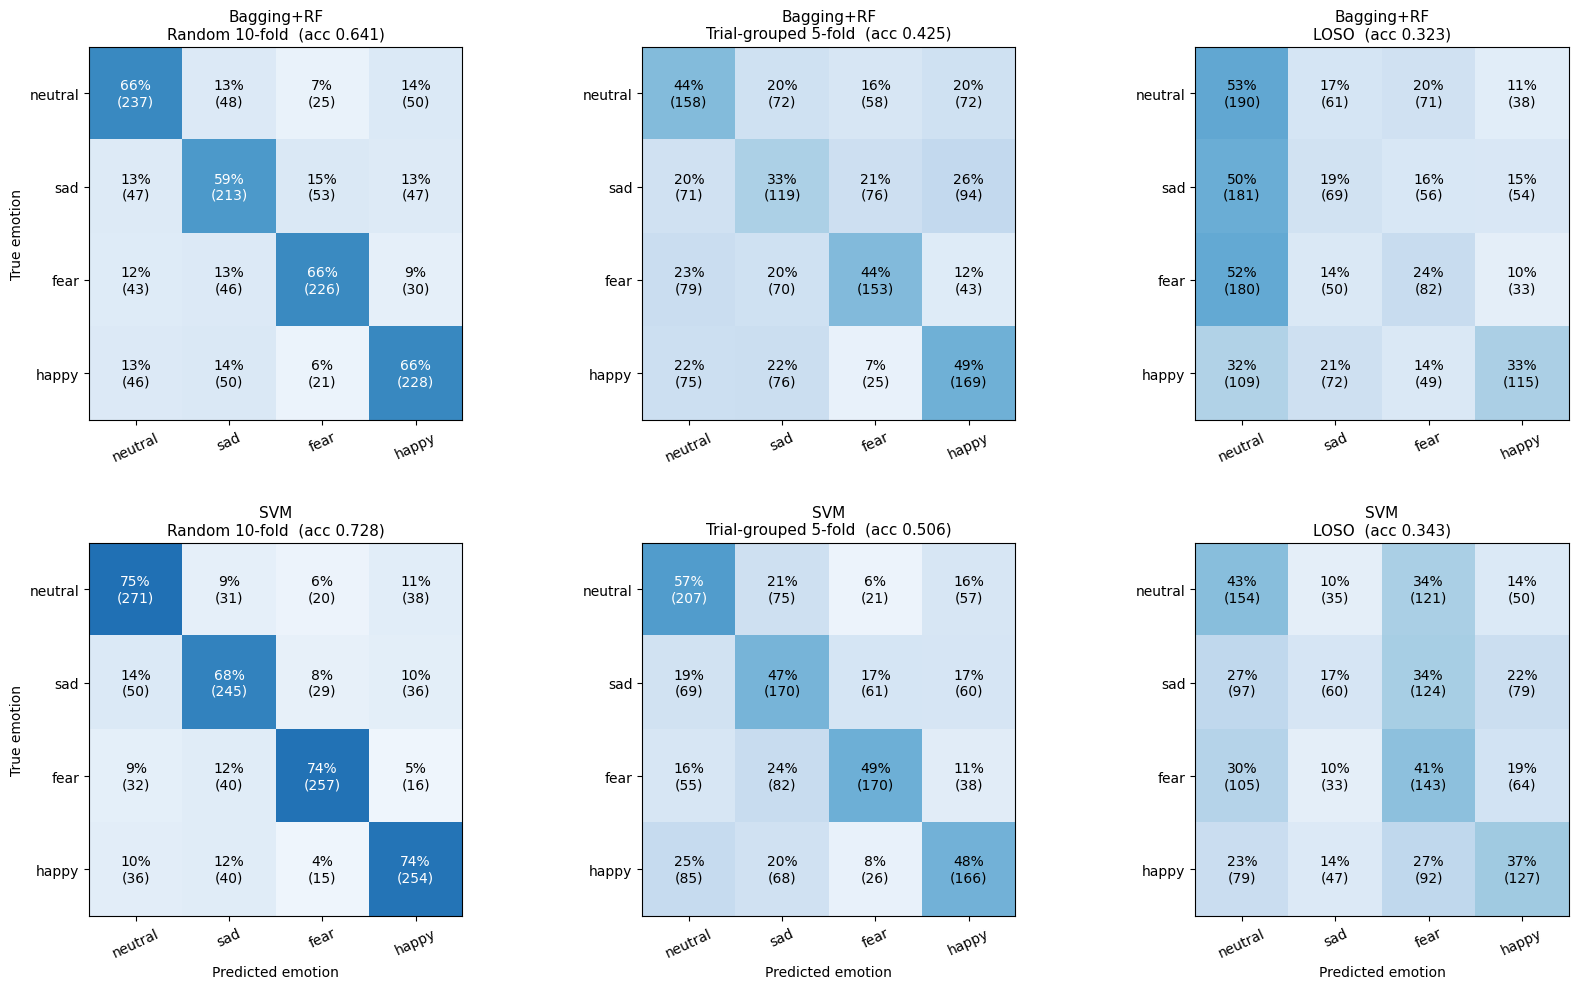

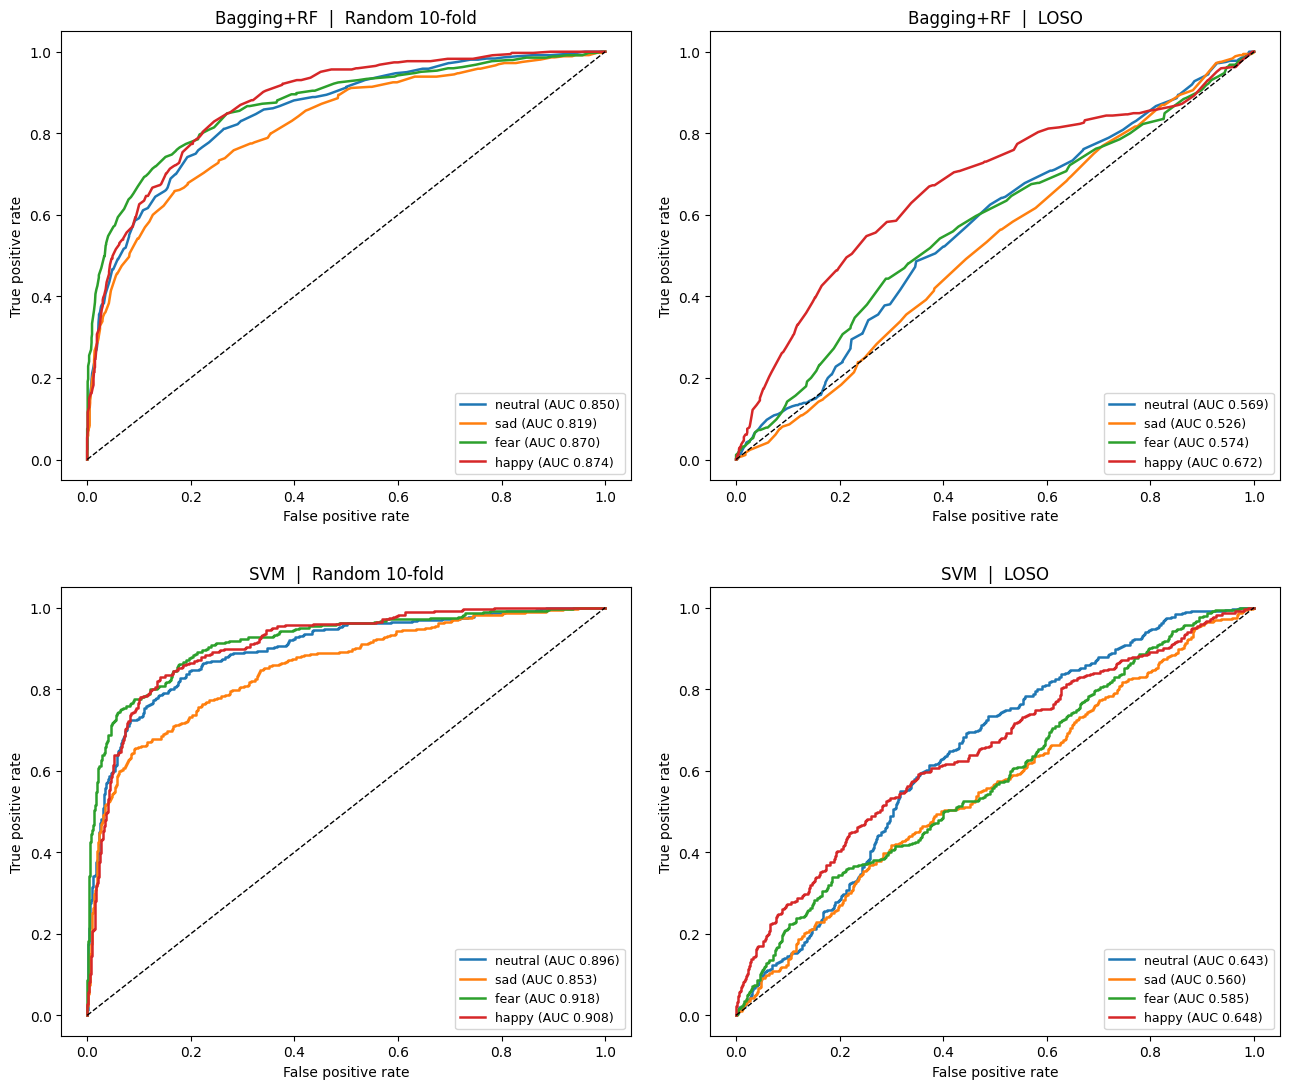

,File,Folder
0.000,metrics_overview.csv,results
1.000,accuracy_with_ci.csv,results
2.000,per_class_reports.csv,results
3.000,confusion_matrices.png,results
4.000,roc_curves.png,results


cell 8 completed in 14 s
variables kept: long, entries, reports, ci_tab


In [17]:
# cell 8: detailed metrics from the saved predictions (no retraining)

import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, roc_auc_score, roc_curve,
                             precision_recall_fscore_support, confusion_matrix)
warnings.filterwarnings("ignore")
t0 = time.time()

# reuse the path from earlier cells, or fall back to the known folder
try:
    DATA_DIR = Path(DATA_DIR)
except NameError:
    DATA_DIR = Path("/content/seed_project/data")
PROJECT_DIR = DATA_DIR.parent
CACHE_DIR = PROJECT_DIR / "cache"
RESULTS_DIR = PROJECT_DIR / "results"

# predictions saved by cell 6 and cell 7
O6 = np.load(CACHE_DIR / "cv10_oof.npz")      # random 10-fold
O7 = np.load(CACHE_DIR / "oof_schemes.npz")   # trial-grouped, loso, loso + z-score
y, subj, trial = O7["y"], O7["subj"], O7["trial"]
assert (O6["y"] == y).all(), "labels in cell 6 and cell 7 files do not match"

CLASS_NAMES = ["neutral", "sad", "fear", "happy"]
MODELS = ["DecisionTree", "RandomForest", "SVM", "Bagging+RF"]
DETAIL = ["Bagging+RF", "SVM"]                          # paper's main model and our best model
SCHEMES = ["Random 10-fold", "Trial-grouped 5-fold", "LOSO"]
Yb = label_binarize(y, classes=[0, 1, 2, 3])


# helpers for headings, notes, neat tables and spacing (output only)
def section(title):
    display(HTML(f"<h2 style='margin-top:44px;margin-bottom:8px;"
                 f"border-bottom:2px solid #888;padding-bottom:4px'>{title}</h2>"))

def note(text):
    display(HTML(f"<p style='margin:6px 0 14px 0;color:#555'>{text}</p>"))

def gap(px=34):
    display(HTML(f"<div style='height:{px}px'></div>"))

def show(df, caption, int_cols=("Support",), index_name=""):
    # the row names (model or emotion) become a normal first column
    df = df.copy()
    df.index.name = index_name
    df = df.reset_index()
    fmt = {c: ("{:,.0f}" if c in int_cols else "{:.3f}")
           for c in df.columns if df[c].dtype != object}
    try:
        sty = (df.style.format(fmt, na_rep="-").set_caption(caption)
               .set_table_styles([
                   dict(selector="caption", props=[("caption-side", "top"), ("text-align", "left"),
                                                   ("font-size", "15px"), ("font-weight", "bold"),
                                                   ("padding", "0 0 8px 0")]),
                   dict(selector="th", props=[("padding", "7px 18px"), ("text-align", "center")]),
                   dict(selector="td", props=[("padding", "7px 18px"), ("text-align", "center")])])
               .hide(axis="index"))
        display(sty)
    except Exception:
        display(df)
    gap()


# collect the saved predictions and scores for every scheme and model
entries = {}
for m in MODELS:
    entries[("Random 10-fold", m)] = (O6[f"F_full__{m}__pred"], O6[f"F_full__{m}__score"])
    entries[("Trial-grouped 5-fold", m)] = (O7[f"TrialGrouped-5fold__{m}__pred"], O7[f"TrialGrouped-5fold__{m}__score"])
    entries[("LOSO", m)] = (O7[f"LOSO__{m}__pred"], O7[f"LOSO__{m}__score"])
entries[("LOSO + subject z-score", "SVM")] = (O7["LOSO+subject-zscore__SVM(subj-z)__pred"],
                                              O7["LOSO+subject-zscore__SVM(subj-z)__score"])
ALL_SCHEMES = SCHEMES + ["LOSO + subject z-score"]

# every entry must have one prediction per instance and 4 scores
for k, (p, s) in entries.items():
    assert len(p) == len(y) and s.shape == (len(y), 4), f"bad shape for {k}"


# all the overall metrics for one model and scheme
def metrics(pred, score):
    return dict(Accuracy=accuracy_score(y, pred), MacroF1=f1_score(y, pred, average="macro"),
                WeightedF1=f1_score(y, pred, average="weighted"), Kappa=cohen_kappa_score(y, pred),
                MacroAUC=roc_auc_score(Yb, score, average="macro"))

long = pd.DataFrame([dict(Scheme=sc, Model=m, **metrics(p, s)) for (sc, m), (p, s) in entries.items()])


# 1. overview tables, one per metric
section("1. Overview: every model under every evaluation scheme")
note("Chance level for 4 balanced classes: accuracy 0.250, kappa 0.000, AUC 0.500. "
     "'Random 10-fold' is the paper's protocol and is inflated because related segments are in both train and test.")

for metric, title in [("Accuracy", "Accuracy"), ("MacroF1", "Macro-averaged F1"),
                      ("Kappa", "Cohen's Kappa"), ("MacroAUC", "Macro one-vs-rest ROC-AUC")]:
    piv = long.pivot(index="Model", columns="Scheme", values=metric).reindex(MODELS)[ALL_SCHEMES]
    show(piv, title, index_name="Model")


# 2. accuracy with 95% confidence intervals
section("2. Accuracy with 95% confidence intervals")
note("Intervals come from resampling whole clips 2000 times. With only 5 subjects they are optimistic "
     "for the LOSO column, because differences between subjects are not captured.")

g = subj * 100 + trial                                   # one group = one clip of one subject
ug, inv = np.unique(g, return_inverse=True)
gn = np.bincount(inv).astype(float)                      # segments in each clip
boot = np.random.default_rng(42).integers(0, len(ug), (2000, len(ug)))

def acc_ci(pred):
    gc = np.bincount(inv, weights=(pred == y).astype(float))   # correct segments in each clip
    a = gc[boot].sum(1) / gn[boot].sum(1)
    return np.percentile(a, [2.5, 97.5])

ci_tab = pd.DataFrame(index=MODELS, columns=SCHEMES, dtype=object)
for m in MODELS:
    for sc in SCHEMES:
        p = entries[(sc, m)][0]
        lo, hi = acc_ci(p)
        ci_tab.loc[m, sc] = f"{accuracy_score(y, p):.3f}  [{lo:.3f}, {hi:.3f}]"
show(ci_tab, "Accuracy  [95% CI]", index_name="Model")


# 3. precision, recall and f1 for each emotion
section("3. Per-class precision, recall and F1")
note("Macro average = plain mean over the 4 emotions. Weighted average = weighted by the number of instances in each class.")

def report(pred):
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=[0, 1, 2, 3], zero_division=0)
    df = pd.DataFrame({"Precision": p, "Recall": r, "F1": f, "Support": s}, index=CLASS_NAMES)
    df.loc["macro avg"] = [p.mean(), r.mean(), f.mean(), s.sum()]
    df.loc["weighted avg"] = [np.average(p, weights=s), np.average(r, weights=s),
                              np.average(f, weights=s), s.sum()]
    df.loc["overall accuracy"] = [np.nan, np.nan, accuracy_score(y, pred), s.sum()]
    return df

reports = {}
for m in DETAIL:
    for sc in SCHEMES:
        df = report(entries[(sc, m)][0])
        reports[(m, sc)] = df
        show(df, f"{m}  |  {sc}", index_name="Emotion")


# 4. auc for each emotion against the rest
section("4. Per-class one-vs-rest ROC-AUC")
note("Each emotion is compared against the other three, using the out-of-fold scores.")

for m in DETAIL:
    auc_df = pd.DataFrame({sc: [roc_auc_score(Yb[:, c], entries[(sc, m)][1][:, c]) for c in range(4)]
                           for sc in SCHEMES}, index=CLASS_NAMES)
    auc_df.loc["macro avg"] = auc_df.mean()
    show(auc_df, f"{m}: AUC for each emotion", index_name="Emotion")


# 5. confusion matrices
section("5. Confusion matrices")
note("Rows = true emotion, columns = predicted emotion. Each box shows the share of that true class, then the count. "
     "Saved to results/confusion_matrices.png.")

fig, axes = plt.subplots(len(DETAIL), len(SCHEMES), figsize=(17, 10))
for i, m in enumerate(DETAIL):
    for j, sc in enumerate(SCHEMES):
        cm = confusion_matrix(y, entries[(sc, m)][0], labels=[0, 1, 2, 3])
        cmn = cm / cm.sum(1, keepdims=True)              # share of each true class
        ax = axes[i, j]
        ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        for a in range(4):
            for b in range(4):
                ax.text(b, a, f"{cmn[a, b]*100:.0f}%\n({cm[a, b]})", ha="center", va="center",
                        color="white" if cmn[a, b] > 0.55 else "black", fontsize=10)
        ax.set_xticks(range(4))
        ax.set_yticks(range(4))
        ax.set_xticklabels(CLASS_NAMES, rotation=25)
        ax.set_yticklabels(CLASS_NAMES)
        ax.set_title(f"{m}\n{sc}  (acc {accuracy_score(y, entries[(sc, m)][0]):.3f})", fontsize=11)
        if j == 0:
            ax.set_ylabel("True emotion")
        if i == len(DETAIL) - 1:
            ax.set_xlabel("Predicted emotion")
plt.tight_layout(h_pad=3, w_pad=2)
plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=130)
plt.show()
gap(40)


# 6. roc curves
section("6. ROC curves (one-vs-rest)")
note("Left: the paper's random 10-fold protocol. Right: leave-one-subject-out. Saved to results/roc_curves.png.")

fig, axes = plt.subplots(len(DETAIL), 2, figsize=(13, 11))
for i, m in enumerate(DETAIL):
    for j, sc in enumerate(["Random 10-fold", "LOSO"]):
        ax = axes[i, j]
        sco = entries[(sc, m)][1]
        for c, nm in enumerate(CLASS_NAMES):
            fpr, tpr, _ = roc_curve(Yb[:, c], sco[:, c])
            ax.plot(fpr, tpr, lw=1.8, label=f"{nm} (AUC {roc_auc_score(Yb[:, c], sco[:, c]):.3f})")
        ax.plot([0, 1], [0, 1], "k--", lw=1)             # chance line
        ax.set_title(f"{m}  |  {sc}")
        ax.set_xlabel("False positive rate")
        ax.set_ylabel("True positive rate")
        ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(h_pad=3, w_pad=2)
plt.savefig(RESULTS_DIR / "roc_curves.png", dpi=130)
plt.show()
gap(40)


# 7. save the tables and plots
section("7. Saving")

long.to_csv(RESULTS_DIR / "metrics_overview.csv", index=False)
ci_tab.to_csv(RESULTS_DIR / "accuracy_with_ci.csv")
pd.concat({f"{m} | {sc}": df for (m, sc), df in reports.items()}).to_csv(RESULTS_DIR / "per_class_reports.csv")

saved = pd.DataFrame({"File": ["metrics_overview.csv", "accuracy_with_ci.csv", "per_class_reports.csv",
                               "confusion_matrices.png", "roc_curves.png"],
                      "Folder": ["results"] * 5})
show(saved, "Files saved by this cell")

print(f"cell 8 completed in {time.time() - t0:.0f} s")
print("variables kept: long, entries, reports, ci_tab")

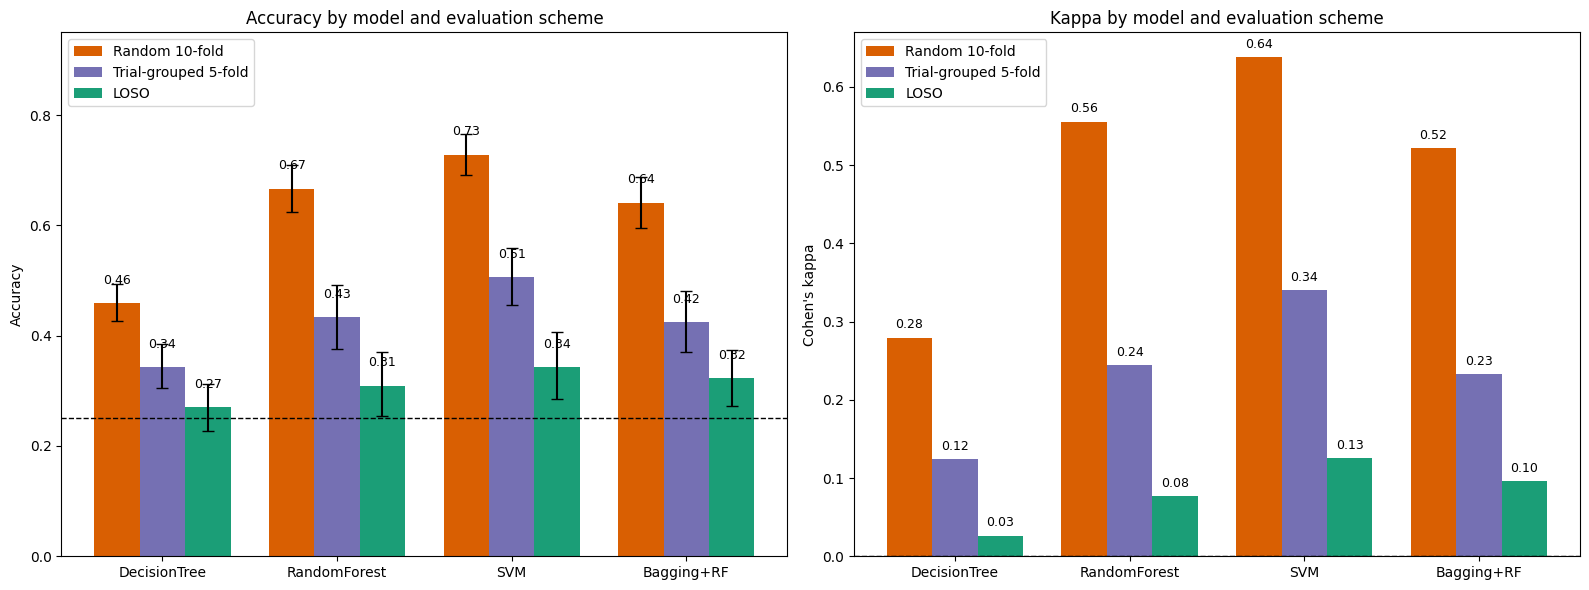

,Random 10-fold,Trial-grouped 5-fold,LOSO,Drop (random -> LOSO)
DecisionTree,0.460,0.343,0.270,0.189
RandomForest,0.667,0.433,0.309,0.357
SVM,0.728,0.506,0.343,0.385
Bagging+RF,0.641,0.425,0.323,0.318


,Paper (3-class SEED),"Ours, random 10-fold (4-class)","Ours, LOSO (4-class)",Paper minus ours (random 10-fold)
DecisionTree,0.809,0.460,0.270,0.349
RandomForest,0.878,0.667,0.309,0.211
SVM,0.889,0.728,0.343,0.161
Bagging+RF,0.996,0.641,0.323,0.355


,File,Size (MB),Training instances,Fit time (s)
Model,,,,
SVM,final_SVM.joblib,20.6,"1,410",9
Bagging+RF,final_Bagging_RF.joblib,0.7,"1,410",11


SVM         : reloaded model gives identical predictions on 200 instances -> True
Bagging+RF  : reloaded model gives identical predictions on 200 instances -> True

End-to-end recomputation (raw segment -> MSPCA -> MCOV) vs cached features, max |difference| over 3 segments: 1.85e-06
(small differences are expected: cached features were computed from float32-stored denoised signals)


results/ : model_comparison.png, final_comparison_table.csv, paper_vs_ours.csv, summary.md (plus Cell 8 files)
models/  : final_SVM.joblib, final_Bagging_RF.joblib, README.txt
bundle   : /content/seed_project/project_outputs.zip (22.0 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Reproducibility checks passed: True
Cell 9 complete in 31 s.


In [16]:
# ============ CELL 9: COMPARISON CHARTS, PAPER-VS-OURS TABLE, FINAL MODELS, SAVE + REPRODUCIBILITY CHECK ============
import json, time, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
warnings.filterwarnings("ignore")
t0 = time.time()

RUN_PAPER_SIZE_CHECK = False     # True = also compare 10 vs 100 trees per bag on one fold (~2.5 extra minutes)

# ---------- 0. Paths, data, config ----------
try:
    DATA_DIR = Path(DATA_DIR)
except NameError:
    DATA_DIR = Path("/content/seed_project/data")
PROJECT_DIR = DATA_DIR.parent
CACHE_DIR = PROJECT_DIR / "cache"; RESULTS_DIR = PROJECT_DIR / "results"; MODELS_DIR = PROJECT_DIR / "models"
for d in (RESULTS_DIR, MODELS_DIR): d.mkdir(exist_ok=True)
O7 = np.load(CACHE_DIR / "oof_schemes.npz"); O6 = np.load(CACHE_DIR / "cv10_oof.npz")
y, subj, trial = O7["y"], O7["subj"], O7["trial"]
F_full = np.load(CACHE_DIR / "F_full.npy")
cfg = json.load(open(CACHE_DIR / "model_config.json"))
BAG_TREES, SEED = cfg["bag_rf_trees"], cfg["seed"]
CLASS_NAMES = ["neutral", "sad", "fear", "happy"]
MODELS = ["DecisionTree", "RandomForest", "SVM", "Bagging+RF"]
SCHEMES = ["Random 10-fold", "Trial-grouped 5-fold", "LOSO"]

def clip5(Z): return np.clip(Z, -5.0, 5.0)

def section(title):
    display(HTML(f"<h2 style='margin-top:44px;margin-bottom:8px;border-bottom:2px solid #888;padding-bottom:4px'>{title}</h2>"))
def note(text):
    display(HTML(f"<p style='margin:6px 0 14px 0;color:#555'>{text}</p>"))
def gap(px=34):
    display(HTML(f"<div style='height:{px}px'></div>"))
def show(df, caption):
    fmt = {c: "{:.3f}" for c in df.columns if df[c].dtype != object}
    try:
        display(df.style.format(fmt, na_rep="–").set_caption(caption).set_table_styles([
            dict(selector="caption", props=[("caption-side", "top"), ("text-align", "left"),
                                            ("font-size", "15px"), ("font-weight", "bold"), ("padding", "0 0 8px 0")]),
            dict(selector="th", props=[("padding", "7px 18px"), ("text-align", "center")]),
            dict(selector="td", props=[("padding", "7px 18px"), ("text-align", "center")])]))
    except Exception:
        display(df)
    gap()

# ---------- 1. Rebuild metrics + bootstrap CIs from the saved predictions ----------
pred = {}
for m in MODELS:
    pred[("Random 10-fold", m)] = O6[f"F_full__{m}__pred"]
    pred[("Trial-grouped 5-fold", m)] = O7[f"TrialGrouped-5fold__{m}__pred"]
    pred[("LOSO", m)] = O7[f"LOSO__{m}__pred"]
g = subj * 100 + trial
_, inv = np.unique(g, return_inverse=True)
gn = np.bincount(inv).astype(float)
boot = np.random.default_rng(42).integers(0, len(gn), (2000, len(gn)))
def ci(p):
    a = np.bincount(inv, weights=(p == y).astype(float))[boot].sum(1) / gn[boot].sum(1)
    return np.percentile(a, [2.5, 97.5])
acc = pd.DataFrame({sc: [accuracy_score(y, pred[(sc, m)]) for m in MODELS] for sc in SCHEMES}, index=MODELS)
lo = pd.DataFrame({sc: [ci(pred[(sc, m)])[0] for m in MODELS] for sc in SCHEMES}, index=MODELS)
hi = pd.DataFrame({sc: [ci(pred[(sc, m)])[1] for m in MODELS] for sc in SCHEMES}, index=MODELS)
ov = pd.read_csv(RESULTS_DIR / "metrics_overview.csv")
kap = ov.pivot(index="Model", columns="Scheme", values="Kappa").reindex(MODELS)[SCHEMES]

# ---------- 2. Comparison charts ----------
section("1. Model comparison across evaluation schemes")
note("Left: accuracy with 95% confidence intervals (resampled clips). Right: Cohen's kappa. "
     "Dashed line = chance level (accuracy 0.25, kappa 0). Saved to results/model_comparison.png.")
cols = {"Random 10-fold": "#d95f02", "Trial-grouped 5-fold": "#7570b3", "LOSO": "#1b9e77"}
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
x = np.arange(len(MODELS)); w = 0.26
for k, sc in enumerate(SCHEMES):
    v = acc[sc].values
    ax[0].bar(x + (k - 1) * w, v, w, label=sc, color=cols[sc],
              yerr=[v - lo[sc].values, hi[sc].values - v], capsize=4)
    for xi, vi in zip(x + (k - 1) * w, v):
        ax[0].text(xi, vi + 0.035, f"{vi:.2f}", ha="center", fontsize=9)
    ax[1].bar(x + (k - 1) * w, kap[sc].values, w, label=sc, color=cols[sc])
    for xi, vi in zip(x + (k - 1) * w, kap[sc].values):
        ax[1].text(xi, vi + 0.012, f"{vi:.2f}", ha="center", fontsize=9)
ax[0].axhline(0.25, color="k", ls="--", lw=1); ax[0].set_ylim(0, 0.95); ax[0].set_ylabel("Accuracy")
ax[0].set_title("Accuracy by model and evaluation scheme")
ax[1].axhline(0.0, color="k", ls="--", lw=1); ax[1].set_ylabel("Cohen's kappa"); ax[1].set_title("Kappa by model and evaluation scheme")
for a in ax:
    a.set_xticks(x); a.set_xticklabels(MODELS); a.legend(loc="upper left")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "model_comparison.png", dpi=130); plt.show()
gap(40)

# ---------- 3. Final comparison table ----------
section("2. Final comparison table (accuracy)")
note("Same numbers as the chart. 'Drop' = how much accuracy falls from the paper's random 10-fold protocol to leave-one-subject-out.")
final_tab = acc.copy(); final_tab["Drop (random -> LOSO)"] = acc["Random 10-fold"] - acc["LOSO"]
show(final_tab, "Accuracy by evaluation scheme (2,480 MCOV features)")
final_tab.to_csv(RESULTS_DIR / "final_comparison_table.csv")

# ---------- 4. Paper vs ours ----------
section("3. Our results versus the paper's reported numbers (NOT a like-for-like comparison)")
note("Paper: SEED, 3 classes, 15 subjects, Weka, 10-fold CV (its Tables 1 and 2; Decision Tree shown as C4.5). "
     "Ours: SEED-IV subset, 4 classes, 5 subjects, 1 session, scikit-learn, Bagging+RF with %d trees per bag. "
     "Chance: paper 0.333, ours 0.250." % BAG_TREES)
paper = {"DecisionTree": 0.809, "RandomForest": 0.878, "SVM": 0.889, "Bagging+RF": 0.996}
pv = pd.DataFrame({"Paper (3-class SEED)": [paper[m] for m in MODELS],
                   "Ours, random 10-fold (4-class)": acc["Random 10-fold"].values,
                   "Ours, LOSO (4-class)": acc["LOSO"].values}, index=MODELS)
pv["Paper minus ours (random 10-fold)"] = pv.iloc[:, 0] - pv.iloc[:, 1]
show(pv, "Paper vs our measured accuracy")
pv.to_csv(RESULTS_DIR / "paper_vs_ours.csv")

# ---------- 5. Final models on ALL instances ----------
section("4. Final models (trained on all 1,410 instances) and saved files")
note("These are demonstration models: they have seen all 5 subjects, so their accuracy on these same data would be meaningless. "
     "The honest performance estimates are the cross-validated numbers above.")
def make_svm():
    return make_pipeline(StandardScaler(), FunctionTransformer(clip5), SVC(kernel="rbf", C=100, gamma="scale", random_state=SEED))
def make_bag(n_trees):
    return BaggingClassifier(RandomForestClassifier(n_estimators=n_trees, n_jobs=1, random_state=SEED),
                             n_estimators=10, bootstrap=True, n_jobs=-1, random_state=SEED)
finals, rows = {}, []
for name, mk in [("SVM", make_svm), ("Bagging+RF", lambda: make_bag(BAG_TREES))]:
    t = time.time(); model = mk().fit(F_full, y); fit_s = time.time() - t
    path = MODELS_DIR / f"final_{name.replace('+', '_')}.joblib"
    joblib.dump({"model": model, "class_names": CLASS_NAMES, "n_features": F_full.shape[1],
                 "feature_description": "log10 MCOV PSD, 62 channels x 40 points (0-75 Hz), AR order 15, after sym4 MSPCA level 5",
                 "trained_on": "5 subjects, session 1 of the SEED-IV copy; demonstration model"}, path, compress=3)
    finals[name] = (model, path)
    rows.append({"Model": name, "File": path.name, "Size (MB)": path.stat().st_size / 1e6,
                 "Training instances": len(y), "Fit time (s)": fit_s})
ft = pd.DataFrame(rows).set_index("Model")
display(ft.style.format({"Size (MB)": "{:.1f}", "Fit time (s)": "{:.0f}", "Training instances": "{:,.0f}"}).set_caption("Saved models"))
gap()
(MODELS_DIR / "README.txt").write_text(
    "Models saved with joblib. Load with: d = joblib.load(path); d['model'].predict(features)\n"
    "The SVM pipeline contains a function named clip5 defined in the notebook; before loading in a NEW session, define:\n"
    "    import numpy as np\n    def clip5(Z): return np.clip(Z, -5.0, 5.0)\n"
    "Input: log10-PSD features of shape (n, 2480) = 62 channels x 40 frequency points. Classes: 0 neutral, 1 sad, 2 fear, 3 happy.\n"
    "Trained on 5 subjects only; use for demonstration, not as a general emotion detector.\n")

# ---------- 6. Reproducibility checks ----------
section("5. Reproducibility checks")
ok_all = True
for name, (model, path) in finals.items():
    loaded = joblib.load(path)["model"]
    same = np.array_equal(loaded.predict(F_full[:200]), model.predict(F_full[:200]))
    ok_all &= same
    print(f"{name:12s}: reloaded model gives identical predictions on 200 instances -> {same}")
print()
try:    # end-to-end: raw segment -> MSPCA -> MCOV -> features, compared with cached features
    Xraw = X if "X" in globals() else np.load(CACHE_DIR / "X_raw.npy", mmap_mode="r")
    d = []
    for i in (0, 700, 1409):
        den, _ = mspca_denoise(np.asarray(Xraw[i], dtype=np.float64), rule="kaiser")
        a, s2 = mcov_ar(den)
        f = np.log10(mcov_psd(a, s2)).reshape(-1)
        d.append(np.abs(f - F_full[i]).max())
    print("End-to-end recomputation (raw segment -> MSPCA -> MCOV) vs cached features, max |difference| over 3 segments: %.2e" % max(d))
    print("(small differences are expected: cached features were computed from float32-stored denoised signals)")
except NameError:
    print("End-to-end check skipped: mspca_denoise / mcov_ar are not in memory (runtime was restarted; re-run Cells 4 and 5 to enable it).")
gap()

# ---------- 7. Optional: paper-size Bagging check on one fold ----------
if RUN_PAPER_SIZE_CHECK:
    section("6. Optional check: 10 vs 100 trees per bag (one random-10-fold fold only)")
    note("Single fold of ~141 instances: differences of a few points are within noise.")
    tr, te = next(iter(StratifiedKFold(10, shuffle=True, random_state=SEED).split(F_full, y)))
    out = []
    for nt in (BAG_TREES, 100):
        t = time.time(); m_ = make_bag(nt).fit(F_full[tr], y[tr])
        out.append({"RF trees per bag": nt, "Accuracy (fold 0)": accuracy_score(y[te], m_.predict(F_full[te])), "Seconds": time.time() - t})
    show(pd.DataFrame(out).set_index("RF trees per bag"), "Bagging+RF size check")

# ---------- 8. Summary file + download bundle ----------
best_r = acc["Random 10-fold"].idxmax(); best_l = acc["LOSO"].idxmax()
summary = f"""# Results summary (auto-generated)

Dataset actually used: SEED-IV copy from Kaggle (phhasian0710/seed-iv), 5 subjects, session 1, 4 classes, 1,410 segments of 1,024 samples at 200 Hz.
Pipeline: 75 Hz low-pass -> Symlets-4 MSPCA (level 5, Kaiser rule) -> MCOV (AR order 15, 40 PSD points, 0-75 Hz) -> classifiers.
Bagging+RF configuration: 10 bags, {BAG_TREES} trees per bag (the paper used 100 trees).

Accuracy by evaluation scheme (chance = 0.25):

{acc.round(3).to_markdown()}

Best model under the paper's random 10-fold protocol: {best_r} ({acc.loc[best_r, 'Random 10-fold']:.3f}).
Best model under leave-one-subject-out: {best_l} ({acc.loc[best_l, 'LOSO']:.3f}).
The paper's 99.6% (3-class SEED, Bagging+RF) was NOT reproduced: our Bagging+RF reached {acc.loc['Bagging+RF', 'Random 10-fold']:.3f} under random 10-fold on a different dataset.
"""
try:
    (RESULTS_DIR / "summary.md").write_text(summary)
except Exception:
    summary = summary.replace(acc.round(3).to_markdown(), acc.round(3).to_string())
    (RESULTS_DIR / "summary.md").write_text(summary)

zip_path = PROJECT_DIR / "project_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in list(RESULTS_DIR.glob("*")) + list(MODELS_DIR.glob("*")) + list(CACHE_DIR.glob("*.json")) + [CACHE_DIR / "subset_files.csv"]:
        if p.exists(): z.write(p, p.relative_to(PROJECT_DIR))
section("Saved files")
print("results/ : model_comparison.png, final_comparison_table.csv, paper_vs_ours.csv, summary.md (plus Cell 8 files)")
print("models/  : final_SVM.joblib, final_Bagging_RF.joblib, README.txt")
print("bundle   : %s (%.1f MB)" % (zip_path, zip_path.stat().st_size / 1e6))
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception as e:
    print("Automatic download not available:", repr(e), "- use the Colab file browser to download the zip.")
print("\nReproducibility checks passed:", ok_all)
print("Cell 9 complete in %.0f s." % (time.time() - t0))

In [18]:
# ============ CELL 10: FINAL REPORT (auto-filled from your saved results) + FINAL BUNDLE ============
import json, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

try:
    DATA_DIR = Path(DATA_DIR)
except NameError:
    DATA_DIR = Path("/content/seed_project/data")
PROJECT_DIR = DATA_DIR.parent
CACHE_DIR = PROJECT_DIR / "cache"; RESULTS_DIR = PROJECT_DIR / "results"; MODELS_DIR = PROJECT_DIR / "models"

# ---------- 1. Load saved results ----------
acc = pd.read_csv(RESULTS_DIR / "final_comparison_table.csv", index_col=0)
ov = pd.read_csv(RESULTS_DIR / "metrics_overview.csv")
cit = pd.read_csv(RESULTS_DIR / "accuracy_with_ci.csv", index_col=0)
cfg = json.load(open(CACHE_DIR / "model_config.json"))
BAG_TREES = cfg["bag_rf_trees"]
MODELS = ["DecisionTree", "RandomForest", "SVM", "Bagging+RF"]
SUBJECT_ID_ACC = 0.926        # measured in Cell 7 (RF on 40-feature set, 5-fold, target = subject)
PAPER = {"DecisionTree": 0.809, "RandomForest": 0.878, "SVM": 0.889, "Bagging+RF": 0.996}

def md_table(df, floatfmt="{:.3f}", index_name=""):
    cols = [index_name] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for idx, row in df.iterrows():
        cells = [str(idx)] + [floatfmt.format(v) if isinstance(v, (int, float, np.floating)) and not pd.isna(v)
                              else ("–" if (not isinstance(v, str) and pd.isna(v)) else str(v)) for v in row.values]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

R = acc.loc[MODELS, "Random 10-fold"]; G = acc.loc[MODELS, "Trial-grouped 5-fold"]; L = acc.loc[MODELS, "LOSO"]
best_R, best_L = R.idxmax(), L.idxmax()
kap = ov.pivot(index="Model", columns="Scheme", values="Kappa").reindex(MODELS)[["Random 10-fold", "Trial-grouped 5-fold", "LOSO"]]
auc = ov.pivot(index="Model", columns="Scheme", values="MacroAUC").reindex(MODELS)[["Random 10-fold", "Trial-grouped 5-fold", "LOSO"]]
zs = ov[(ov.Scheme == "LOSO + subject z-score")].iloc[0]
paper_tab = pd.DataFrame({"Paper (3-class SEED, 10-fold)": [PAPER[m] for m in MODELS],
                          "Ours, random 10-fold (4-class)": R.values, "Ours, LOSO (4-class)": L.values}, index=MODELS)

# ---------- 2. Report text ----------
report = f"""
# EEG-Based Emotion Recognition with MSPCA, Modified Covariance (MCOV) and Ensemble Classifiers
### A re-implementation of Subasi & Qaisar (2024), evaluated on a subset of SEED-IV

---

## 1. Objective
Re-implement the pipeline of Subasi & Qaisar (J. Ambient Intell. Humaniz. Comput., 2024): **EEG → Symlets-4 MSPCA denoising → MCOV feature extraction → ensemble classifiers**, and measure its performance honestly. The paper reports 99.6% accuracy for Bagging + Random Forest. We treat that as a reference value, not as a target.

## 2. Application and motivation
Recognising emotions from EEG supports human-computer interaction, neuromarketing, healthcare (monitoring mood-related conditions) and security. EEG is noisy and varies strongly between people, so reliable denoising, informative features and robust classifiers all matter.

## 3. Dataset (and an important deviation)
The paper uses **SEED** (3 emotions, 15 subjects). We could not obtain SEED, which requires an application to the BCMI lab. We used a **Kaggle copy of SEED-IV** (`phhasian0710/seed-iv`; we have not verified its provenance or licence terms) instead.

| | Paper (SEED) | This project (SEED-IV subset) |
|---|---|---|
| Emotion classes | 3: negative, neutral, positive | 4: neutral, sad, fear, happy |
| Channels / sampling rate | 62 / 200 Hz | 62 / 200 Hz (already downsampled) |
| Subjects used | 15 | **5** (subjects 1-5) |
| Sessions used | 3 | **1** (session 1) |
| Instances | not stated | **1,410** (5 subjects x 24 trials x up to 12 segments) |

Each instance is a **1,024-sample (5.12 s) segment** of one trial and takes the label of that trial (labels come from the dataset ReadMe). Segments were taken at evenly spaced positions in each trial, at most 12 per trial, to keep every notebook cell under about 4 minutes. A spectrum check showed energy above 75 Hz, so a 75 Hz low-pass filter was applied; no resampling was needed.

## 4. Methodology
1. **MSPCA denoising.** Each 62-channel segment is decomposed with a 5-level Symlets-4 wavelet transform. At every scale, PCA is run across channels and only the leading components are kept (Kaiser rule: eigenvalue above the mean). The signal is then rebuilt by wavelet synthesis. Tests: perfect reconstruction when all components are kept (error 1.2e-12), and a synthetic test where SNR rose from 4.97 dB to 9.09 dB.
2. **MCOV features.** For each channel an autoregressive model of **order 15** is estimated with the modified covariance method (paper Eqs. 3-9). The PSD is computed from it (Eq. 10) at **40 frequencies between 0 and 75 Hz**. Tests: recovery of a known AR(2) process, and agreement (about 1e-9) with an independent least-squares solution.
3. **Classifiers.** Decision Tree, Random Forest (100 trees), SVM and **Bagging + Random Forest** (10 bags, {BAG_TREES} trees per bag).
4. **Features given to the classifiers:** log10 of the PSD, 62 channels x 40 points = **2,480 features per instance**. We also tried a 40-feature channel-averaged version (the most literal reading of the paper); it was clearly worse (about 36-50% accuracy under random 10-fold).

## 5. Implementation details and differences from the paper
| Item | Paper | This project |
|---|---|---|
| Dataset | SEED, 3 classes | SEED-IV Kaggle copy, 4 classes, 5 subjects, 1 session |
| Instance definition | not stated | 1,024-sample segment of one trial |
| Features per instance | "40 PSD coefficients" | 40 PSD points per channel (2,480 total); channel-averaged 40 also tested |
| PSD frequency grid | not stated | 40 equally spaced points, 0-75 Hz (our choice) |
| MSPCA details | Sym4, 5 levels, PCA per scale | same, plus Kaiser rule, per-scale standardisation, no thresholding (our choices) |
| Low-pass filter | 75 Hz, then resample to 200 Hz | 75 Hz Butterworth (data already 200 Hz) |
| SVM | Weka, Puk kernel, C = 100 | scikit-learn, RBF kernel, C = 100 |
| Random Forest | Weka, 100 trees | scikit-learn, 100 trees |
| Bagging + RF | Weka Bagging with RF | 10 bags x {BAG_TREES}-tree RF (reduced for Colab time) |
| Decision tree | C4.5 | CART (scikit-learn) |
| Cross-validation | 10-fold | stratified 10-fold (random) plus two stricter schemes |

## 6. Evaluation strategy
- **Random stratified 10-fold** is the paper's protocol. Segments from the same trial appear in both training and test sets, so it is **leaky** and we do not treat it as a generalisation estimate.
- **Trial-grouped 5-fold.** Whole clips are held out, with the same subjects in training and test.
- **Leave-one-subject-out (LOSO).** Train on 4 subjects and test on the unseen fifth. This is the only scheme that measures cross-subject generalisation.
- Scaling for the SVM is fitted inside each training fold. Random seed 42 throughout. Confidence intervals come from resampling whole clips (2,000 resamples).

## 7. Results (measured in this project)
**Accuracy** (chance = 0.25):

{md_table(acc.loc[MODELS], index_name="Model")}

**Cohen's kappa:**

{md_table(kap, index_name="Model")}

**Macro one-vs-rest ROC-AUC:**

{md_table(auc, index_name="Model")}

**Accuracy with 95% confidence intervals:**

{md_table(cit.loc[MODELS], index_name="Model")}

Main observations:
- Under the paper's random 10-fold protocol the best model was **{best_R} ({R[best_R]:.3f})**. Bagging+RF reached {R['Bagging+RF']:.3f}, below plain Random Forest ({R['RandomForest']:.3f}) and the SVM ({R['SVM']:.3f}).
- Accuracy falls sharply under stricter evaluation: SVM {R['SVM']:.3f} (random) → {G['SVM']:.3f} (trial-grouped) → **{L['SVM']:.3f} (LOSO)**; Bagging+RF {R['Bagging+RF']:.3f} → {G['Bagging+RF']:.3f} → **{L['Bagging+RF']:.3f}**.
- Under LOSO, all models are only a few points above chance (0.25). The confidence intervals of SVM, Bagging+RF and Random Forest overlap heavily, so **we cannot rank them under LOSO**.
- Under LOSO the models were biased: Bagging+RF over-predicted *neutral* (recall 0.53, precision 0.29) and rarely recognised *sad* (recall 0.19).
- A random forest could identify **which subject** a segment came from with accuracy {SUBJECT_ID_ACC:.3f} (chance 0.20) using only the 40-feature version. The features therefore carry a strong subject signature. This is why random splits look much better than LOSO. Normalising features per subject raised LOSO SVM accuracy from {L['SVM']:.3f} to {zs['Accuracy']:.3f}, which helps only slightly.

## 8. Comparison with the paper
{md_table(paper_tab, index_name="Model")}

The paper's **99.6% was not reproduced**. Our Bagging+RF reached {R['Bagging+RF']:.3f} under the same style of protocol, and the datasets are not equivalent (3 vs 4 classes, 15 vs 5 subjects), so the numbers are not directly comparable. Our checks do show that the MSPCA and MCOV code behave as specified, so we do not attribute the gap to an implementation error, but we cannot rule one out either.

Possible reasons for the gap. **These are hypotheses; we did not test them:**
1. Different dataset: 4 emotions instead of 3, and SEED-IV is a different experiment from SEED.
2. Far fewer data: 5 subjects, 1 session, 1,410 instances.
3. The paper does not define an "instance" or give the PSD frequency grid. If it used many heavily overlapping segments per trial, a random 10-fold split would be far more inflated than ours.
4. Our design choices (Kaiser rule, log transform, 40 points per channel) may differ from the authors'.
5. Bagging+RF used {BAG_TREES} trees per bag instead of 100, and scikit-learn differs from Weka.
6. The paper reports only the random 10-fold protocol. Whether its 99.6% is inflated by leakage cannot be determined from the paper alone.

## 9. Limitations
- Different dataset from the paper, with an unverified Kaggle copy.
- Only 5 subjects and 1 session, with a cap of 12 segments per trial. LOSO has only 5 test folds, so its confidence intervals understate the real uncertainty.
- Some recordings contain large artifacts (subject 5 has amplitudes up to about 18,900 µV). No artifact rejection was applied because the paper does not describe one.
- The modified covariance AR fit is not guaranteed to be stable (about 0.3% of sampled fits had a pole at or beyond the unit circle), which can create very large PSD values.
- Hyperparameters were not tuned, and Bagging+RF used a reduced size.
- The final saved models are trained on all 5 subjects, so they are demonstrations, not unbiased estimates.

## 10. Future work
Run the full 15 subjects x 3 sessions; obtain the original SEED from BCMI and repeat the experiment; test different instance definitions and PSD grids; add artifact handling; evaluate cross-session generalisation; try domain adaptation across subjects; compare with differential-entropy features and deep models.

## 11. Conclusion
The full MSPCA → MCOV → ensemble pipeline was implemented and verified with unit tests. On a small SEED-IV subset, the best model under the paper's random 10-fold protocol was {best_R} at {R[best_R]:.3f}. The paper's 99.6% for Bagging+RF was not reproduced (ours: {R['Bagging+RF']:.3f}). When whole clips or whole subjects are held out, accuracy drops to {G['SVM']:.3f} and {L['SVM']:.3f} for the SVM, only modestly above the 0.25 chance level in the cross-subject case. The honest conclusion is that this feature set supports emotion recognition within a known subject much better than across subjects.

---

# Simple explanations (for your professor)

**EEG.** Electrodes on the scalp record tiny electrical signals from the brain over time. We have 62 electrodes recorded at 200 samples per second.

**Wavelet transform.** It splits a signal into frequency bands (fast and slow components) while keeping track of *when* things happen. We use the Symlets-4 wavelet and split each signal into 5 levels, giving about 6 bands.

**PCA.** It finds the few directions along which many correlated signals vary together. Keeping only the strongest directions keeps shared structure and throws away much of the independent noise.

**MSPCA.** Multiscale PCA does the PCA separately inside each wavelet band, keeps the important components of each band, and rebuilds the signal. In short: split into frequency bands, remove noise in each band using PCA across channels, and put the bands back together. Using plain PCA alone would not do this.

**Autoregressive (AR) model.** It predicts each sample from the previous 15 samples. The 15 weights summarise the signal's rhythm. The modified covariance method picks those weights so that *both* forward and backward prediction errors are small, which makes the estimate more accurate on short signals.

**PSD.** Power spectral density shows how much signal power sits at each frequency. From the AR weights we compute the PSD at 40 frequencies between 0 and 75 Hz. These numbers are the features.

**MCOV.** The whole feature method: fit the AR model with the modified covariance method, then take the PSD of that model.

**Decision tree.** A flowchart of yes/no questions on the features. It is simple but unstable.

**Random Forest.** Many decision trees, each trained on a random sample of the data and features, voting together. It is more stable than a single tree.

**Bagging.** Train many copies of a model on random re-samples of the training set and let them vote. Bagging + Random Forest is a forest of forests. It mainly reduces variance.

**Cross-validation.** Split the data into parts; train on some, test on the rest, and rotate. The catch with EEG: a random split puts near-identical neighbouring segments in both train and test, which inflates the score. Leave-one-subject-out is stricter because the test person was never seen in training.

**Cohen's kappa.** Accuracy corrected for chance agreement. 0 means chance level and 1 means perfect.

**ROC-AUC.** How well the model ranks the right class above the others. 0.5 is chance and 1.0 is perfect.
"""

# ---------- 3. Display, save, bundle ----------
display(Markdown(report))
(RESULTS_DIR / "final_report.md").write_text(report)

zip_path = PROJECT_DIR / "project_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in list(RESULTS_DIR.glob("*")) + list(MODELS_DIR.glob("*")) + list(CACHE_DIR.glob("*.json")) + [CACHE_DIR / "subset_files.csv"]:
        if p.exists(): z.write(p, p.relative_to(PROJECT_DIR))
print("Saved: results/final_report.md | bundle updated:", zip_path, "(%.1f MB)" % (zip_path.stat().st_size / 1e6))
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception as e:
    print("Automatic download not available:", repr(e), "- download project_outputs.zip from the Colab file browser.")
print("PROJECT COMPLETE.")


# EEG-Based Emotion Recognition with MSPCA, Modified Covariance (MCOV) and Ensemble Classifiers
### A re-implementation of Subasi & Qaisar (2024), evaluated on a subset of SEED-IV

---

## 1. Objective
Re-implement the pipeline of Subasi & Qaisar (J. Ambient Intell. Humaniz. Comput., 2024): **EEG → Symlets-4 MSPCA denoising → MCOV feature extraction → ensemble classifiers**, and measure its performance honestly. The paper reports 99.6% accuracy for Bagging + Random Forest. We treat that as a reference value, not as a target.

## 2. Application and motivation
Recognising emotions from EEG supports human-computer interaction, neuromarketing, healthcare (monitoring mood-related conditions) and security. EEG is noisy and varies strongly between people, so reliable denoising, informative features and robust classifiers all matter.

## 3. Dataset (and an important deviation)
The paper uses **SEED** (3 emotions, 15 subjects). We could not obtain SEED, which requires an application to the BCMI lab. We used a **Kaggle copy of SEED-IV** (`phhasian0710/seed-iv`; we have not verified its provenance or licence terms) instead.

| | Paper (SEED) | This project (SEED-IV subset) |
|---|---|---|
| Emotion classes | 3: negative, neutral, positive | 4: neutral, sad, fear, happy |
| Channels / sampling rate | 62 / 200 Hz | 62 / 200 Hz (already downsampled) |
| Subjects used | 15 | **5** (subjects 1-5) |
| Sessions used | 3 | **1** (session 1) |
| Instances | not stated | **1,410** (5 subjects x 24 trials x up to 12 segments) |

Each instance is a **1,024-sample (5.12 s) segment** of one trial and takes the label of that trial (labels come from the dataset ReadMe). Segments were taken at evenly spaced positions in each trial, at most 12 per trial, to keep every notebook cell under about 4 minutes. A spectrum check showed energy above 75 Hz, so a 75 Hz low-pass filter was applied; no resampling was needed.

## 4. Methodology
1. **MSPCA denoising.** Each 62-channel segment is decomposed with a 5-level Symlets-4 wavelet transform. At every scale, PCA is run across channels and only the leading components are kept (Kaiser rule: eigenvalue above the mean). The signal is then rebuilt by wavelet synthesis. Tests: perfect reconstruction when all components are kept (error 1.2e-12), and a synthetic test where SNR rose from 4.97 dB to 9.09 dB.
2. **MCOV features.** For each channel an autoregressive model of **order 15** is estimated with the modified covariance method (paper Eqs. 3-9). The PSD is computed from it (Eq. 10) at **40 frequencies between 0 and 75 Hz**. Tests: recovery of a known AR(2) process, and agreement (about 1e-9) with an independent least-squares solution.
3. **Classifiers.** Decision Tree, Random Forest (100 trees), SVM and **Bagging + Random Forest** (10 bags, 10 trees per bag).
4. **Features given to the classifiers:** log10 of the PSD, 62 channels x 40 points = **2,480 features per instance**. We also tried a 40-feature channel-averaged version (the most literal reading of the paper); it was clearly worse (about 36-50% accuracy under random 10-fold).

## 5. Implementation details and differences from the paper
| Item | Paper | This project |
|---|---|---|
| Dataset | SEED, 3 classes | SEED-IV Kaggle copy, 4 classes, 5 subjects, 1 session |
| Instance definition | not stated | 1,024-sample segment of one trial |
| Features per instance | "40 PSD coefficients" | 40 PSD points per channel (2,480 total); channel-averaged 40 also tested |
| PSD frequency grid | not stated | 40 equally spaced points, 0-75 Hz (our choice) |
| MSPCA details | Sym4, 5 levels, PCA per scale | same, plus Kaiser rule, per-scale standardisation, no thresholding (our choices) |
| Low-pass filter | 75 Hz, then resample to 200 Hz | 75 Hz Butterworth (data already 200 Hz) |
| SVM | Weka, Puk kernel, C = 100 | scikit-learn, RBF kernel, C = 100 |
| Random Forest | Weka, 100 trees | scikit-learn, 100 trees |
| Bagging + RF | Weka Bagging with RF | 10 bags x 10-tree RF (reduced for Colab time) |
| Decision tree | C4.5 | CART (scikit-learn) |
| Cross-validation | 10-fold | stratified 10-fold (random) plus two stricter schemes |

## 6. Evaluation strategy
- **Random stratified 10-fold** is the paper's protocol. Segments from the same trial appear in both training and test sets, so it is **leaky** and we do not treat it as a generalisation estimate.
- **Trial-grouped 5-fold.** Whole clips are held out, with the same subjects in training and test.
- **Leave-one-subject-out (LOSO).** Train on 4 subjects and test on the unseen fifth. This is the only scheme that measures cross-subject generalisation.
- Scaling for the SVM is fitted inside each training fold. Random seed 42 throughout. Confidence intervals come from resampling whole clips (2,000 resamples).

## 7. Results (measured in this project)
**Accuracy** (chance = 0.25):

| Model | Random 10-fold | Trial-grouped 5-fold | LOSO | Drop (random -> LOSO) |
|---|---|---|---|---|
| DecisionTree | 0.460 | 0.343 | 0.270 | 0.189 |
| RandomForest | 0.667 | 0.433 | 0.309 | 0.357 |
| SVM | 0.728 | 0.506 | 0.343 | 0.385 |
| Bagging+RF | 0.641 | 0.425 | 0.323 | 0.318 |

**Cohen's kappa:**

| Model | Random 10-fold | Trial-grouped 5-fold | LOSO |
|---|---|---|---|
| DecisionTree | 0.279 | 0.124 | 0.027 |
| RandomForest | 0.555 | 0.244 | 0.077 |
| SVM | 0.638 | 0.340 | 0.125 |
| Bagging+RF | 0.521 | 0.233 | 0.096 |

**Macro one-vs-rest ROC-AUC:**

| Model | Random 10-fold | Trial-grouped 5-fold | LOSO |
|---|---|---|---|
| DecisionTree | 0.640 | 0.562 | 0.514 |
| RandomForest | 0.872 | 0.669 | 0.560 |
| SVM | 0.894 | 0.736 | 0.609 |
| Bagging+RF | 0.853 | 0.668 | 0.585 |

**Accuracy with 95% confidence intervals:**

| Model | Random 10-fold | Trial-grouped 5-fold | LOSO |
|---|---|---|---|
| DecisionTree | 0.460  [0.426, 0.494] | 0.343  [0.305, 0.385] | 0.270  [0.227, 0.312] |
| RandomForest | 0.667  [0.623, 0.709] | 0.433  [0.376, 0.491] | 0.309  [0.255, 0.370] |
| SVM | 0.728  [0.690, 0.766] | 0.506  [0.455, 0.559] | 0.343  [0.285, 0.407] |
| Bagging+RF | 0.641  [0.595, 0.687] | 0.425  [0.371, 0.482] | 0.323  [0.272, 0.375] |

Main observations:
- Under the paper's random 10-fold protocol the best model was **SVM (0.728)**. Bagging+RF reached 0.641, below plain Random Forest (0.667) and the SVM (0.728).
- Accuracy falls sharply under stricter evaluation: SVM 0.728 (random) → 0.506 (trial-grouped) → **0.343 (LOSO)**; Bagging+RF 0.641 → 0.425 → **0.323**.
- Under LOSO, all models are only a few points above chance (0.25). The confidence intervals of SVM, Bagging+RF and Random Forest overlap heavily, so **we cannot rank them under LOSO**.
- Under LOSO the models were biased: Bagging+RF over-predicted *neutral* (recall 0.53, precision 0.29) and rarely recognised *sad* (recall 0.19).
- A random forest could identify **which subject** a segment came from with accuracy 0.926 (chance 0.20) using only the 40-feature version. The features therefore carry a strong subject signature. This is why random splits look much better than LOSO. Normalising features per subject raised LOSO SVM accuracy from 0.343 to 0.384, which helps only slightly.

## 8. Comparison with the paper
| Model | Paper (3-class SEED, 10-fold) | Ours, random 10-fold (4-class) | Ours, LOSO (4-class) |
|---|---|---|---|
| DecisionTree | 0.809 | 0.460 | 0.270 |
| RandomForest | 0.878 | 0.667 | 0.309 |
| SVM | 0.889 | 0.728 | 0.343 |
| Bagging+RF | 0.996 | 0.641 | 0.323 |

The paper's **99.6% was not reproduced**. Our Bagging+RF reached 0.641 under the same style of protocol, and the datasets are not equivalent (3 vs 4 classes, 15 vs 5 subjects), so the numbers are not directly comparable. Our checks do show that the MSPCA and MCOV code behave as specified, so we do not attribute the gap to an implementation error, but we cannot rule one out either.

Possible reasons for the gap. **These are hypotheses; we did not test them:**
1. Different dataset: 4 emotions instead of 3, and SEED-IV is a different experiment from SEED.
2. Far fewer data: 5 subjects, 1 session, 1,410 instances.
3. The paper does not define an "instance" or give the PSD frequency grid. If it used many heavily overlapping segments per trial, a random 10-fold split would be far more inflated than ours.
4. Our design choices (Kaiser rule, log transform, 40 points per channel) may differ from the authors'.
5. Bagging+RF used 10 trees per bag instead of 100, and scikit-learn differs from Weka.
6. The paper reports only the random 10-fold protocol. Whether its 99.6% is inflated by leakage cannot be determined from the paper alone.

## 9. Limitations
- Different dataset from the paper, with an unverified Kaggle copy.
- Only 5 subjects and 1 session, with a cap of 12 segments per trial. LOSO has only 5 test folds, so its confidence intervals understate the real uncertainty.
- Some recordings contain large artifacts (subject 5 has amplitudes up to about 18,900 µV). No artifact rejection was applied because the paper does not describe one.
- The modified covariance AR fit is not guaranteed to be stable (about 0.3% of sampled fits had a pole at or beyond the unit circle), which can create very large PSD values.
- Hyperparameters were not tuned, and Bagging+RF used a reduced size.
- The final saved models are trained on all 5 subjects, so they are demonstrations, not unbiased estimates.

## 10. Future work
Run the full 15 subjects x 3 sessions; obtain the original SEED from BCMI and repeat the experiment; test different instance definitions and PSD grids; add artifact handling; evaluate cross-session generalisation; try domain adaptation across subjects; compare with differential-entropy features and deep models.

## 11. Conclusion
The full MSPCA → MCOV → ensemble pipeline was implemented and verified with unit tests. On a small SEED-IV subset, the best model under the paper's random 10-fold protocol was SVM at 0.728. The paper's 99.6% for Bagging+RF was not reproduced (ours: 0.641). When whole clips or whole subjects are held out, accuracy drops to 0.506 and 0.343 for the SVM, only modestly above the 0.25 chance level in the cross-subject case. The honest conclusion is that this feature set supports emotion recognition within a known subject much better than across subjects.

---

# Simple explanations (for your professor)

**EEG.** Electrodes on the scalp record tiny electrical signals from the brain over time. We have 62 electrodes recorded at 200 samples per second.

**Wavelet transform.** It splits a signal into frequency bands (fast and slow components) while keeping track of *when* things happen. We use the Symlets-4 wavelet and split each signal into 5 levels, giving about 6 bands.

**PCA.** It finds the few directions along which many correlated signals vary together. Keeping only the strongest directions keeps shared structure and throws away much of the independent noise.

**MSPCA.** Multiscale PCA does the PCA separately inside each wavelet band, keeps the important components of each band, and rebuilds the signal. In short: split into frequency bands, remove noise in each band using PCA across channels, and put the bands back together. Using plain PCA alone would not do this.

**Autoregressive (AR) model.** It predicts each sample from the previous 15 samples. The 15 weights summarise the signal's rhythm. The modified covariance method picks those weights so that *both* forward and backward prediction errors are small, which makes the estimate more accurate on short signals.

**PSD.** Power spectral density shows how much signal power sits at each frequency. From the AR weights we compute the PSD at 40 frequencies between 0 and 75 Hz. These numbers are the features.

**MCOV.** The whole feature method: fit the AR model with the modified covariance method, then take the PSD of that model.

**Decision tree.** A flowchart of yes/no questions on the features. It is simple but unstable.

**Random Forest.** Many decision trees, each trained on a random sample of the data and features, voting together. It is more stable than a single tree.

**Bagging.** Train many copies of a model on random re-samples of the training set and let them vote. Bagging + Random Forest is a forest of forests. It mainly reduces variance.

**Cross-validation.** Split the data into parts; train on some, test on the rest, and rotate. The catch with EEG: a random split puts near-identical neighbouring segments in both train and test, which inflates the score. Leave-one-subject-out is stricter because the test person was never seen in training.

**Cohen's kappa.** Accuracy corrected for chance agreement. 0 means chance level and 1 means perfect.

**ROC-AUC.** How well the model ranks the right class above the others. 0.5 is chance and 1.0 is perfect.


Saved: results/final_report.md | bundle updated: /content/seed_project/project_outputs.zip (22.1 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PROJECT COMPLETE.
